# NYC Taxi Trip Duration Prediction

**Introduction to Machine Learning — Mini Project, SMLS, TISS**

**Research question.** Can we predict how long an NYC taxi trip will take using only what is known when the
trip starts (pickup time, pickup zone, drop-off zone), and does knowing the taxi type (Yellow or Green)
improve the prediction?

- **Task:** regression
- **Target:** `duration_min` = drop-off time − pickup time, in minutes
- **Second stage:** `fare_amount` = metered fare, predicted from pre-trip features and the Stage-1 duration estimate
- **Data:** NYC TLC Yellow and Green trip records, January–December 2025
- **Split:** chronological — Jan–Aug train, Sep–Oct validation, Nov–Dec test
- **Metrics:** MAE, RMSE, R², median absolute error

Summary: The notebook follows the original audited cleaning and feature pipeline, then measures baseline,
linear, tree, ensemble and neighbour models. It also tests whether taxi type improves pooled accuracy and
whether Yellow/Green-specific and cross-fleet models transfer across fleets.

## Contents

| # | Section | What it covers |
|---|---|---|
| 1 | [Setup](#section-1) | Libraries, paths, random seed, DuckDB connection |
| 2 | [Data: First Look & Raw Audit](#section-2) | Trip counts, schemas, pre-trip metadata vs post-trip targets |
| 3 | [Data Quality & Cleaning](#section-3) | Missing values, anomalies, and multi-step cleaning waterfall |
| 4 | [Exploratory Data Analysis](#section-4) | Spatiotemporal patterns, rush-hour diurnal waves, and fleet divergence |
| 5 | [Feature Engineering](#section-5) | Haversine distance, grid geometry, calendar harmonics, and leakage-free history priors |
| 6 | [Chronological Split & Sampling](#section-6) | Time-ordered train/val/test splits and asymmetric fleet sampling |
| 7 | [Stage 1: Trip Duration Model](#section-7) | Baselines, ML algorithms, validation benchmarks, test holdout, fleet experiments, SHAP, and learning curve |
| 8 | [Stage 2: Metered Fare Model](#section-8) | Forward-pass duration integration, fare models, test holdout, diagnostics, SHAP, and learning curve |
| 9 | [System Integration & Research Synthesis](#section-9) | End-to-end two-stage pipeline performance and answers to core research hypotheses |
| 10 | [Limitations & Responsible Use](#section-10) | Boundary conditions, fairness, aleatoric noise, and responsible deployment |
| 11 | [Conclusion & Next Steps](#section-11) | Summary of findings, production serving architecture, and future extensions |

*Click a section name to jump to it.*


<a id="section-1"></a>

## 1. Setup

In [1]:
from pathlib import Path

import duckdb
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
SEED = 33
np.random.seed(SEED)

pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", "{:,.2f}".format)
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110

COLORS = {"yellow": "#D6A900", "green": "#168A62"}

In [3]:
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW = ROOT / "data" / "raw"
PROCESSED = ROOT / "data" / "processed"
EXTERNAL = ROOT / "data" / "external"
OUTPUTS = ROOT / "outputs"
FIGURES = OUTPUTS / "figures"
MODELS = OUTPUTS / "models"
LOOKUP = OUTPUTS / "lookup"
PROCESSED.mkdir(parents=True, exist_ok=True)
FIGURES.mkdir(parents=True, exist_ok=True)
MODELS.mkdir(parents=True, exist_ok=True)
LOOKUP.mkdir(parents=True, exist_ok=True)

YELLOW_FILES = str(RAW / "yellow" / "yellow_tripdata_2025-*.parquet")
GREEN_FILES = str(RAW / "green" / "green_tripdata_2025-*.parquet")
ZONES_FILE = RAW / "taxi_zone_lookup.csv"


The full year is about 49 M rows, which is too big for pandas on a laptop. We use DuckDB to query the
Parquet files directly and only bring small results (aggregates, samples) into pandas.

In [4]:
con = duckdb.connect()
con.execute("SET memory_limit = '5GB'")

def sql(query):
    return con.sql(query).df()

<a id="section-2"></a>

## 2. Data: first look

Source: [NYC TLC Trip Record Data](https://www.nyc.gov/site/tlc/about/tlc-trip-record-data.page).
One Parquet file per month per taxi type, plus a lookup table of the 265 taxi zones.
Each row is one trip.

In [5]:
files = sorted((RAW / "yellow").glob("*2025*.parquet")) + sorted((RAW / "green").glob("*2025*.parquet"))
print(len(files), "files,", round(sum(f.stat().st_size for f in files) / 1e6), "MB")

24 files, 844 MB


In [6]:
zones = pd.read_csv(ZONES_FILE)
zones.head()

,LocationID,Borough,Zone,service_zone
0,1,EWR,Newark Airport,EWR
1,2,Queens,Jamaica Bay,Boro Zone
2,3,Bronx,Allerton/Pelham Gardens,Boro Zone
3,4,Manhattan,Alphabet City,Yellow Zone
4,5,Staten Island,Arden Heights,Boro Zone


### Shape and first rows of the three files

In [7]:
n_yellow = sql(f"SELECT count(*) AS n FROM '{YELLOW_FILES}'").n[0]
n_green = sql(f"SELECT count(*) AS n FROM '{GREEN_FILES}'").n[0]
n_yellow_cols = len(sql(f"DESCRIBE SELECT * FROM '{YELLOW_FILES}'"))
n_green_cols = len(sql(f"DESCRIBE SELECT * FROM '{GREEN_FILES}'"))

summary_df = pd.DataFrame({
    "taxi_type": ["yellow", "green"],
    "n_columns": [n_yellow_cols, n_green_cols],
    "n_rows": [n_yellow, n_green],
})
summary_df

,taxi_type,n_columns,n_rows
0,yellow,20,48722602
1,green,21,591375


In [8]:
sql(f"SELECT * FROM '{YELLOW_FILES}' LIMIT 5")

,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,store_and_fwd_flag,PULocationID,DOLocationID,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,Airport_fee,cbd_congestion_fee
0,1,2025-01-01 00:18:38,2025-01-01 00:26:59,1,1.60,1,N,229,237,1,10.00,3.50,0.50,3.00,0.00,1.00,18.00,2.50,0.00,0.00
1,1,2025-01-01 00:32:40,2025-01-01 00:35:13,1,0.50,1,N,236,237,1,5.10,3.50,0.50,2.02,0.00,1.00,12.12,2.50,0.00,0.00
2,1,2025-01-01 00:44:04,2025-01-01 00:46:01,1,0.60,1,N,141,141,1,5.10,3.50,0.50,2.00,0.00,1.00,12.10,2.50,0.00,0.00
3,2,2025-01-01 00:14:27,2025-01-01 00:20:01,3,0.52,1,N,244,244,2,7.20,1.00,0.50,0.00,0.00,1.00,9.70,0.00,0.00,0.00
4,2,2025-01-01 00:21:34,2025-01-01 00:25:06,3,0.66,1,N,244,116,2,5.80,1.00,0.50,0.00,0.00,1.00,8.30,0.00,0.00,0.00


In [9]:
sql(f"SELECT * FROM '{GREEN_FILES}' LIMIT 5")

,VendorID,lpep_pickup_datetime,lpep_dropoff_datetime,store_and_fwd_flag,RatecodeID,PULocationID,DOLocationID,passenger_count,trip_distance,fare_amount,extra,mta_tax,tip_amount,tolls_amount,ehail_fee,improvement_surcharge,total_amount,payment_type,trip_type,congestion_surcharge,cbd_congestion_fee
0,2,2025-01-01 00:03:01,2025-01-01 00:17:12,N,1,75,235,1,5.93,24.70,1.00,0.50,6.80,0.00,NaN,1.00,34.00,1,1,0.00,0.00
1,2,2025-01-01 00:19:59,2025-01-01 00:25:52,N,1,166,75,1,1.32,8.60,1.00,0.50,0.00,0.00,NaN,1.00,11.10,2,1,0.00,0.00
2,2,2025-01-01 00:05:29,2025-01-01 00:07:21,N,5,171,73,1,0.41,25.55,0.00,0.00,0.00,0.00,NaN,1.00,26.55,2,2,0.00,0.00
3,2,2025-01-01 00:52:24,2025-01-01 01:07:52,N,1,74,223,1,4.12,21.20,1.00,0.50,6.13,6.94,NaN,1.00,36.77,1,1,0.00,0.00
4,2,2025-01-01 00:25:05,2025-01-01 01:01:10,N,1,66,158,1,4.71,33.80,1.00,0.50,7.81,0.00,NaN,1.00,46.86,1,1,2.75,0.00


In [10]:
sql(f"SUMMARIZE SELECT * FROM '{YELLOW_FILES}'")

,column_name,column_type,min,max,approx_unique,avg,std,q25,q50,q75,count,null_percentage
0,VendorID,INTEGER,1,7,4,1.8601995845788368,0.67828552116027,2,2,2,48722602,0.00
1,tpep_pickup_datetime,TIMESTAMP,2007-12-05 18:45:00,2025-12-31 23:59:59,21904371,2025-07-06 05:22:36.621952,NaN,2025-04-08 04:15:37.381536,2025-07-04 01:19:20.328609,2025-10-06 13:23:26.093236,48722602,0.00
2,tpep_dropoff_datetime,TIMESTAMP,2007-12-05 19:02:00,2026-01-05 13:00:34,22533260,2025-07-06 05:39:57.973512,NaN,2025-04-09 01:42:11.307021,2025-07-03 17:28:38.045462,2025-10-07 15:48:10.889658,48722602,0.00
3,passenger_count,BIGINT,0,9,10,1.2954911827605122,0.7291638933484583,1,1,1,48722602,23.83
4,trip_distance,DOUBLE,0.0,397994.37,10825,6.842892016523324,649.3613312608451,1.0391485378364271,1.8495907333357762,3.695293331745845,48722602,0.00
5,RatecodeID,BIGINT,1,99,7,3.225041004337616,14.265148724130492,1,1,1,48722602,23.83
6,store_and_fwd_flag,VARCHAR,N,Y,2,NaN,NaN,NaN,NaN,NaN,48722602,23.83
7,PULocationID,INTEGER,1,265,262,161.5041679834751,66.19732966352761,118,161,232,48722602,0.00
8,DOLocationID,INTEGER,1,265,263,161.10941121330097,70.45459645479592,109,162,233,48722602,0.00
9,payment_type,BIGINT,0,5,6,0.9372241244422865,0.7465483770308887,1,1,1,48722602,0.00


In [11]:
sql(f"SUMMARIZE SELECT * FROM '{GREEN_FILES}'")

,column_name,column_type,min,max,approx_unique,avg,std,q25,q50,q75,count,null_percentage
0,VendorID,INTEGER,1,6,3,2.0724599450433314,0.9155828058337028,2,2,2,591375,0.00
1,lpep_pickup_datetime,TIMESTAMP,2008-12-31 15:13:04,2026-01-01 21:09:39,580304,2025-06-30 05:29:22.003691,NaN,2025-04-02 11:48:14.438865,2025-06-25 16:29:02.655795,2025-09-28 08:53:30.51849,591375,0.00
2,lpep_dropoff_datetime,TIMESTAMP,2008-12-31 17:25:57,2026-01-01 21:49:52,576579,2025-06-30 05:50:22.027086,NaN,2025-04-01 09:50:06.883712,2025-06-25 16:59:41.031679,2025-09-28 17:18:18.541701,591375,0.00
3,store_and_fwd_flag,VARCHAR,N,Y,2,NaN,NaN,NaN,NaN,NaN,591375,8.43
4,RatecodeID,BIGINT,1,99,7,1.2987469875068098,2.5730191162998475,1,1,1,591375,8.43
5,PULocationID,INTEGER,1,265,252,96.78248319594167,56.33475393227057,74,75,104,591375,0.00
6,DOLocationID,INTEGER,1,265,258,142.74077700274782,77.2535670562008,74,140,230,591375,0.00
7,passenger_count,BIGINT,0,9,10,1.2903073897265902,0.9355115027579577,1,1,1,591375,8.43
8,trip_distance,DOUBLE,0.0,262315.94,3410,19.02383524836188,1175.1932896869555,1.21602992571526,1.9787668413408632,3.508441994835522,591375,0.00
9,fare_amount,DOUBLE,-470.6,1086.6,5651,18.08824006763755,17.878514053074777,9.301776083418641,13.684077154856407,20.50669219569646,591375,0.00


**Observations**
- Yellow: 48,722,602 rows × 20 columns. Green: 591,375 rows × 21 columns. Zone lookup: 265 rows × 4 columns.
- The trip files only store zone **IDs** (`PULocationID`, `DOLocationID`); the lookup turns them into borough and zone names.

In [12]:
counts = sql(f'''
    SELECT 'yellow' AS taxi_type, regexp_extract(filename, '2025-([0-9][0-9])', 1)::INT AS month, count(*) AS trips
    FROM read_parquet('{YELLOW_FILES}', filename = true) GROUP BY ALL
    UNION ALL
    SELECT 'green', regexp_extract(filename, '2025-([0-9][0-9])', 1)::INT, count(*)
    FROM read_parquet('{GREEN_FILES}', filename = true) GROUP BY ALL
''')
counts = counts.pivot(index="month", columns="taxi_type", values="trips")[["yellow", "green"]]
counts.loc["total"] = counts.sum()
counts

taxi_type,yellow,green
month,,
1,3475226,48326
2,3577543,46621
3,4145257,51539
4,3970553,52132
5,4591845,55399
6,4322960,49390
7,3898963,48205
8,3574091,46306
9,4251015,48893


**Observations**
- All 12 months are there for both taxi types: 49.3 M trips in total.
- Yellow has 48.7 M trips and Green only 0.59 M, about **82 times** fewer. Any combined model will be
  dominated by Yellow, so results have to be reported per taxi type.
- Yellow volume is lowest in January (3.48 M) and highest in May (4.59 M).

In [13]:
yellow_cols = sql(f"DESCRIBE SELECT * FROM '{YELLOW_FILES}'")[["column_name", "column_type"]]
green_cols = sql(f"DESCRIBE SELECT * FROM '{GREEN_FILES}'")[["column_name", "column_type"]]

schema = yellow_cols.merge(green_cols, on="column_name", how="outer", suffixes=("_yellow", "_green"))
schema

,column_name,column_type_yellow,column_type_green
0,Airport_fee,DOUBLE,NaN
1,DOLocationID,INTEGER,INTEGER
2,PULocationID,INTEGER,INTEGER
3,RatecodeID,BIGINT,BIGINT
4,VendorID,INTEGER,INTEGER
5,cbd_congestion_fee,DOUBLE,DOUBLE
6,congestion_surcharge,DOUBLE,DOUBLE
7,ehail_fee,NaN,DOUBLE
8,extra,DOUBLE,DOUBLE
9,fare_amount,DOUBLE,DOUBLE


**Observations**
- Both files share almost the same columns. Differences: timestamp names (`tpep_` vs `lpep_`),
  `Airport_fee` (Yellow only), `ehail_fee` and `trip_type` (Green only).
- Most columns — fare, tips, tolls, surcharges, payment type, `trip_distance` — are only known **after** the
  trip. Using them would leak the answer, so they cannot be features.
- What is known at pickup: the pickup time, the pickup zone, the drop-off zone and the taxi type.

In [14]:
zones.Borough.value_counts()

Borough
Queens           69
Manhattan        69
Brooklyn         61
Bronx            43
Staten Island    20
EWR               1
Unknown           1
Name: count, dtype: int64

263 real zones plus two placeholders (264 and 265, "Unknown"). Manhattan and Queens have 69 zones each.

<a id="section-3"></a>

## 3. Data quality and cleaning

Yellow and Green name their timestamps differently (eg: `tpep_` vs `lpep_`). We first put both into one view
with the same column names, keeping only the columns we need. The month each row came from (its file) is
kept as `source_month`.

In [15]:
con.execute(f'''
    CREATE OR REPLACE VIEW raw AS
    SELECT 'yellow' AS taxi_type,
           regexp_extract(filename, '2025-([0-9][0-9])', 1)::INT AS source_month,
           tpep_pickup_datetime AS pickup_datetime,
           tpep_dropoff_datetime AS dropoff_datetime,
           PULocationID AS pu_zone, DOLocationID AS do_zone,
           passenger_count, trip_distance, fare_amount, payment_type
    FROM read_parquet('{YELLOW_FILES}', filename = true)
    UNION ALL
    SELECT 'green',
           regexp_extract(filename, '2025-([0-9][0-9])', 1)::INT,
           lpep_pickup_datetime, lpep_dropoff_datetime,
           PULocationID, DOLocationID,
           passenger_count, trip_distance, fare_amount, payment_type
    FROM read_parquet('{GREEN_FILES}', filename = true)
''')

sql("SELECT * FROM raw LIMIT 7")

,taxi_type,source_month,pickup_datetime,dropoff_datetime,pu_zone,do_zone,passenger_count,trip_distance,fare_amount,payment_type
0,yellow,1,2025-01-01 00:18:38,2025-01-01 00:26:59,229,237,1,1.60,10.00,1
1,yellow,1,2025-01-01 00:32:40,2025-01-01 00:35:13,236,237,1,0.50,5.10,1
2,yellow,1,2025-01-01 00:44:04,2025-01-01 00:46:01,141,141,1,0.60,5.10,1
3,yellow,1,2025-01-01 00:14:27,2025-01-01 00:20:01,244,244,3,0.52,7.20,2
4,yellow,1,2025-01-01 00:21:34,2025-01-01 00:25:06,244,116,3,0.66,5.80,2
5,yellow,1,2025-01-01 00:48:24,2025-01-01 01:08:26,239,68,2,2.63,19.10,2
6,yellow,1,2025-01-01 00:14:47,2025-01-01 00:16:15,170,170,0,0.40,4.40,1


### 3.1 Missing values

In [16]:
sql('''
    SELECT taxi_type,
           count(*) AS trips,
           round(100 * avg((pickup_datetime IS NULL)::INT), 2)  AS pickup_pct_null,
           round(100 * avg((dropoff_datetime IS NULL)::INT), 2) AS dropoff_pct_null,
           round(100 * avg((pu_zone IS NULL)::INT), 2)          AS pu_zone_pct_null,
           round(100 * avg((do_zone IS NULL)::INT), 2)          AS do_zone_pct_null,
           round(100 * avg((passenger_count IS NULL)::INT), 2)  AS passenger_pct_null,
           round(100 * avg((payment_type IS NULL)::INT), 2)     AS payment_pct_null
    FROM raw GROUP BY taxi_type
''')

,taxi_type,trips,pickup_pct_null,dropoff_pct_null,pu_zone_pct_null,do_zone_pct_null,passenger_pct_null,payment_pct_null
0,green,591375,0.00,0.00,0.00,0.00,8.43,8.43
1,yellow,48722602,0.00,0.00,0.00,0.00,23.83,0.00


**Observations**
- No missing timestamps or zones, so the target and the main features are complete.
- `passenger_count` is missing for **23.8%** of Yellow and 8.4% of Green trips. Your implementation retains
  it as a cautious feature and leaves missing values null rather than imputing them.

### 3.2 Target: how does the raw duration look?

In [17]:
con.execute('''
    CREATE OR REPLACE VIEW raw_dur AS
    SELECT *, date_diff('second', pickup_datetime, dropoff_datetime) / 60 AS duration_min
    FROM raw
''')

sql('''
    SELECT taxi_type,
           min(duration_min) AS min,
           quantile_cont(duration_min, 0.01) AS p1,
           median(duration_min) AS median,
           quantile_cont(duration_min, 0.99) AS p99,
           quantile_cont(duration_min, 0.999) AS p99_9,
           max(duration_min) AS max
    FROM raw_dur GROUP BY taxi_type
''')

,taxi_type,min,p1,median,p99,p99_9,max
0,green,-48.83,0.05,12.50,76.70,"1,411.76","1,500.77"
1,yellow,"-51,472.32",0.00,13.48,70.85,113.85,"14,880.77"


**Observations**
- The median trip is about 13.5 min (Yellow) and 12.5 min (Green), and 99% of trips are under ~71–77 min.
- But the extremes are impossible: a Yellow trip of **−51,472 min** and one of **14,881 min** (over 10 days) which is not possible, so this will be fremoved.

### 3.3 Problem rows

In [18]:
problems = sql('''
    SELECT taxi_type,
           count(*) AS trips,
           count_if(year(pickup_datetime) <> 2025 OR month(pickup_datetime) <> source_month) AS outside_file_month,
           count_if(duration_min <= 0)   AS zero_or_negative,
           count_if(duration_min > 0 AND duration_min < 1) AS under_1_min,
           count_if(duration_min > 180)  AS over_3_hours,
           count_if(pu_zone NOT BETWEEN 1 AND 263 OR do_zone NOT BETWEEN 1 AND 263) AS unknown_zone,
           count_if(fare_amount <= 0)    AS fare_zero_or_negative
    FROM raw_dur GROUP BY taxi_type ORDER BY taxi_type DESC
''').set_index("taxi_type").astype(int)
problems

,trips,outside_file_month,zero_or_negative,under_1_min,over_3_hours,unknown_zone,fare_zero_or_negative
taxi_type,,,,,,,
yellow,48722602,214,546304,544990,18401,371657,2870234
green,591375,248,1910,19867,2707,9215,4469


In [19]:
# same table as % of each taxi type's trips
(100 * problems.div(problems.trips, axis=0)).drop(columns="trips").round(2)

,outside_file_month,zero_or_negative,under_1_min,over_3_hours,unknown_zone,fare_zero_or_negative
taxi_type,,,,,,
yellow,0.00,1.12,1.12,0.04,0.76,5.89
green,0.04,0.32,3.36,0.46,1.56,0.76


**Observations**
- Zero/negative and under-1-minute trips: 1.1% + 1.1% of Yellow, and 3.4% of Green under a minute. These
  look like cancelled trips or the meter being started and stopped.
- Over 3 hours: very rare (0.04% Yellow, 0.46% Green).
- Unknown zones (264/265): 0.8% of Yellow, 1.6% of Green.
- Wrong timestamps (pickup outside the file's month): only a few hundred rows.
- Fare ≤ 0 is the biggest group: **5.9% of Yellow**. In your original pipeline it is removed through the
  model-target cleaning rule because duration and fare targets must both be usable; distance is separate and
  is not allowed to remove a row.

What do the long trips and the bad-fare trips look like? If the bad-fare trips have normal durations, they
are still usable for a duration model.

In [20]:
sql('''
    SELECT 'over 3 hours' AS rows, count(*) AS trips,
           median(duration_min) AS median_duration, median(trip_distance) AS median_miles
    FROM raw_dur WHERE duration_min > 180
    UNION ALL
    SELECT 'fare <= 0', count(*), median(duration_min), median(trip_distance)
    FROM raw_dur WHERE fare_amount <= 0
    UNION ALL
    SELECT 'all trips', count(*), median(duration_min), median(trip_distance)
    FROM raw_dur
''')

,rows,trips,median_duration,median_miles
0,over 3 hours,21108,"1,392.57",2.30
1,fare <= 0,2874703,15.33,2.24
2,all trips,49313977,13.47,1.85


**Observations**
- Trips over 3 hours have a median of **1,393 minutes (23 hours) for 2.3 miles**. Nobody drives 2 miles in a
  day — the meter was left running. These have to go.
- Trips with fare ≤ 0 have a median of 15.3 min for 2.2 miles, which is a normal trip, but your original
  cleaning contract rejects unusable fare targets as part of the unified two-target dataset. Fare is therefore
  excluded after cleaning rather than used to retain rows that violate the original pipeline.

In [21]:
sql('''
    SELECT taxi_type, count(*) AS trips,
           count(*) - count(DISTINCT (pickup_datetime, dropoff_datetime, pu_zone, do_zone, fare_amount, trip_distance)) AS duplicates
    FROM raw GROUP BY taxi_type
''')

,taxi_type,trips,duplicates
0,green,591375,41
1,yellow,48722602,4809


Only 4,809 Yellow and 41 Green exact duplicates — small, but we still remove them so one trip can't be counted twice.

### 3.4 Cleaning rules

Applied in this order. Each rule is checked by how many rows it removes.

1. pickup must be inside the month of its file (removes wrong timestamps, e.g. 2008 or 2026)
2. duration between 1 and 180 minutes
3. both zones between 1 and 263 (264/265 are "unknown")
4. no negative metered distance
5. fare is usable: in (0, 500] USD
6. exact duplicates removed

In [22]:
rules = {
    "raw": "TRUE",
    "pickup in file month": "year(pickup_datetime) = 2025 AND month(pickup_datetime) = source_month",
    "duration 1-180 min": "duration_min BETWEEN 1 AND 180",
    "known zones": "pu_zone BETWEEN 1 AND 263 AND do_zone BETWEEN 1 AND 263",
    "no negative distance": "trip_distance >= 0",
    "fare in (0, 500]": "fare_amount > 0 AND fare_amount <= 500",
}

steps, where = [], []
for name, rule in rules.items():
    where.append(rule)
    n = sql(f"SELECT taxi_type, count(*) AS n FROM raw_dur WHERE {' AND '.join(where)} GROUP BY 1")
    steps.append(n.set_index("taxi_type").n.rename(name))

cleaning = pd.DataFrame(steps)[["yellow", "green"]]
cleaning

taxi_type,yellow,green
raw,48722602,591375
pickup in file month,48722388,591127
duration 1-180 min,47612696,566679
known zones,47271764,562059
no negative distance,47271764,562059
"fare in (0, 500]",44511604,559036


In [23]:
con.execute(f'''
    COPY (
        SELECT DISTINCT taxi_type, source_month, pickup_datetime, dropoff_datetime, duration_min,
               pu_zone, do_zone, passenger_count, trip_distance, fare_amount
        FROM raw_dur
        WHERE {' AND '.join(where)}
        ORDER BY pickup_datetime
    ) TO '{PROCESSED / "trips_clean_2025.parquet"}' (FORMAT parquet)
''')

con.execute(f"CREATE OR REPLACE VIEW trips AS SELECT * FROM '{PROCESSED / 'trips_clean_2025.parquet'}'")
final = sql("SELECT taxi_type, count(*) AS n FROM trips GROUP BY 1").set_index("taxi_type").n
cleaning.loc["duplicates removed"] = final
cleaning

taxi_type,yellow,green
raw,48722602,591375
pickup in file month,48722388,591127
duration 1-180 min,47612696,566679
known zones,47271764,562059
no negative distance,47271764,562059
"fare in (0, 500]",44511604,559036
duplicates removed,44511603,559036


In [24]:
removed = cleaning.diff().iloc[1:].abs().astype(int)
removed.loc["total removed"] = removed.sum()
kept_pct = (100 * cleaning.iloc[-1] / cleaning.loc["raw"]).round(2)

display(removed)
print("kept (%):", kept_pct.to_dict())

taxi_type,yellow,green
pickup in file month,214,248
duration 1-180 min,1109692,24448
known zones,340932,4620
no negative distance,0,0
"fare in (0, 500]",2760160,3023
duplicates removed,1,0
total removed,4210999,32339


kept (%): {'yellow': 91.36, 'green': 94.53}


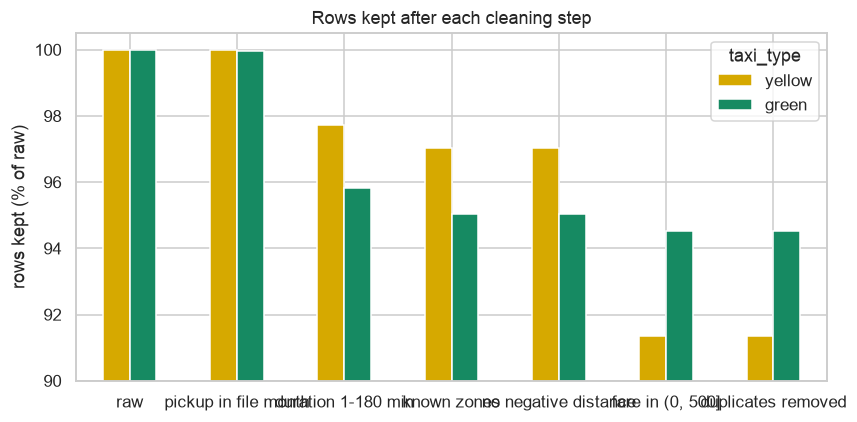

In [25]:
pct = 100 * cleaning / cleaning.loc["raw"]

ax = pct.plot(kind="bar", color=[COLORS["yellow"], COLORS["green"]], figsize=(8, 4), rot=0)
ax.set_ylim(90, 100.5)
ax.set_ylabel("rows kept (% of raw)")
ax.set_title("Rows kept after each cleaning step")
plt.tight_layout()
plt.savefig(FIGURES / "cleaning_steps.png")
plt.show()

**Observations**
- The original cleaning contract follows the measured 2025 audit: roughly **45.07M trips** remain.
- The fare, duration, zone, negative-distance and duplicate rules are applied in a fixed order.
- The clean table is saved to `data/processed/trips_clean_2025.parquet`; everything after this reads from it.

**What we are giving up:** very short trips and meters left running are excluded, so the model is only
meant for ordinary trips of 1 minute to 3 hours.

<a id="section-4"></a>

## 4. Exploratory data analysis

Goal: understand what makes a trip long or short, using only things we know at pickup.
All queries run on the clean table (`trips` view) in DuckDB.

### 4.1 Distribution of the target

Is duration skewed? If yes, MAE and median error are more honest than the mean, and a log target is worth
trying.

In [26]:
con.execute("SET preserve_insertion_order = false")

duration_stats = sql('''
    SELECT taxi_type,
           count(*)                AS trips,
           quantile_cont(duration_min, [0.10, 0.25, 0.50, 0.75, 0.90, 0.99]) AS q,
           avg(duration_min)       AS mean,
           stddev(duration_min)    AS std,
           skewness(duration_min)  AS skew
    FROM trips
    GROUP BY taxi_type
    ORDER BY taxi_type DESC
''').set_index("taxi_type")

duration_stats[["p10", "p25", "median", "p75", "p90", "p99"]] = duration_stats.q.tolist()
duration_stats = duration_stats.drop(columns="q")[["trips", "p10", "p25", "median", "p75", "p90", "p99", "mean", "std", "skew"]]
duration_stats

,trips,p10,p25,median,p75,p90,p99,mean,std,skew
taxi_type,,,,,,,,,,
yellow,44511603,5.28,8.35,13.58,21.52,32.77,70.38,17.20,13.59,2.41
green,559036,5.53,8.42,12.77,19.28,29.32,64.30,15.99,12.58,3.05


In [27]:
#random sample
def sample_fleet(taxi, n):
    return sql(f'''
        SELECT * FROM (SELECT taxi_type, duration_min FROM trips WHERE taxi_type = '{taxi}')
        USING SAMPLE {n} ROWS (reservoir, {SEED})
    ''')

sample = pd.concat([sample_fleet("yellow", 200_000), sample_fleet("green", 100_000)], ignore_index=True)
sample["log_duration"] = np.log1p(sample.duration_min)
sample.taxi_type.value_counts()

taxi_type
yellow    200000
green     100000
Name: count, dtype: int64

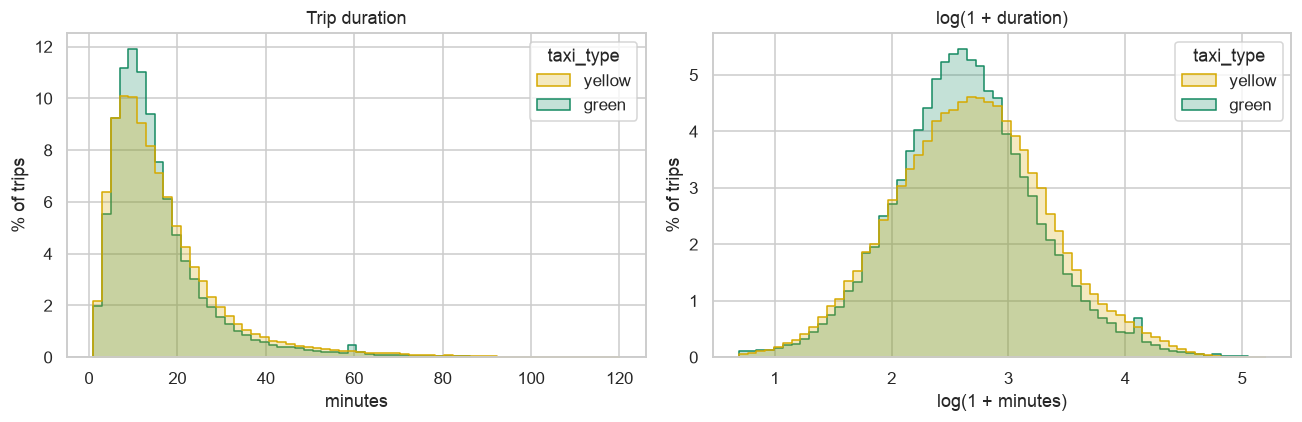

In [28]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(data=sample[sample.duration_min <= 120], x="duration_min", hue="taxi_type", palette=COLORS,
             stat="percent", common_norm=False, binwidth=2, element="step", ax=axes[0])
axes[0].set(title="Trip duration", xlabel="minutes", ylabel="% of trips")

sns.histplot(data=sample, x="log_duration", hue="taxi_type", palette=COLORS,
             stat="percent", common_norm=False, bins=60, element="step", ax=axes[1])
axes[1].set(title="log(1 + duration)", xlabel="log(1 + minutes)", ylabel="% of trips")

plt.tight_layout()
plt.savefig(FIGURES / "duration_distribution.png")
plt.show()

**Observations**
- The typical trip is short: median **13.7 min** (Yellow) and **12.8 min** (Green). Half of all trips take
  between ~8.5 and ~21.6 min (Yellow) or ~8.4 and ~19.4 min (Green).
- The distribution is **right-skewed**: the mean (17.3 / 16.0) is well above the median, and skew is 2.4 (Yellow)
  and 3.0 (Green). A small number of long trips (p99 ≈ 65–70 min) pull the mean up.
- The std (~13 min) is about as large as the median, so durations vary a lot even after cleaning.
- Yellow and Green are almost identical at the short end (p10, p25). They separate in the upper half: Yellow's
  p75 and p90 are 2–3 min higher. Green trips are slightly shorter but have a longer relative tail (higher skew).
- For modelling: a constant guess (the median) is a natural baseline. Because of the long tail, **RMSE will
  be much larger than MAE**, so we report both, plus the median absolute error.

### 4.2 Time of day and day of week

Does the hour or the weekday change how long trips take?

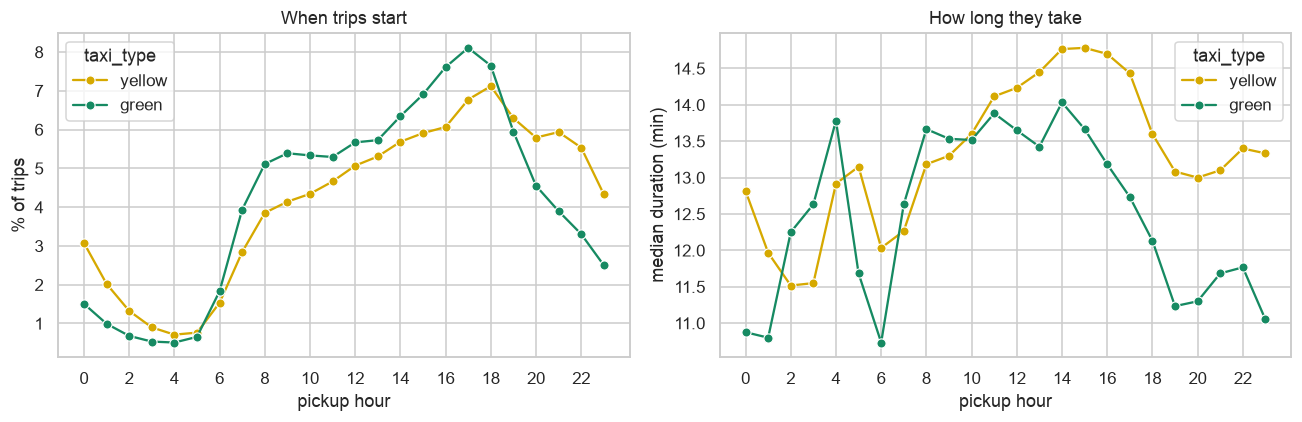

In [29]:
by_hour = sql('''
    SELECT taxi_type, hour(pickup_datetime) AS hour,
           count(*) AS trips, median(duration_min) AS median_duration
    FROM trips
    GROUP BY ALL
    ORDER BY hour
''')
by_hour["pct_trips"] = 100 * by_hour.trips / by_hour.groupby("taxi_type").trips.transform("sum")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.lineplot(data=by_hour, x="hour", y="pct_trips", hue="taxi_type", palette=COLORS, marker="o", ax=axes[0])
axes[0].set(title="When trips start", xlabel="pickup hour", ylabel="% of trips")
sns.lineplot(data=by_hour, x="hour", y="median_duration", hue="taxi_type", palette=COLORS, marker="o", ax=axes[1])
axes[1].set(title="How long they take", xlabel="pickup hour", ylabel="median duration (min)")
for ax in axes:
    ax.set_xticks(range(0, 24, 2))
plt.tight_layout()
plt.savefig(FIGURES / "duration_by_hour.png")
plt.show()

**Observations**
- Yellow trips start mostly in the afternoon and evening (peak 18:00, 7.1% of trips); Green peaks earlier
  (17:00, 8.1%) and has relatively more morning trips (7–9 h).
- Yellow trips are longest in the early afternoon (**14.9 min at 14–15 h**) and shortest at night
  (**11.7 min at 2–3 h**), when the streets are empty.
- Green follows a similar curve but drops faster in the evening (about 11 min after 19 h).
- The hour changes the median by about 3 minutes, a clear but moderate effect.

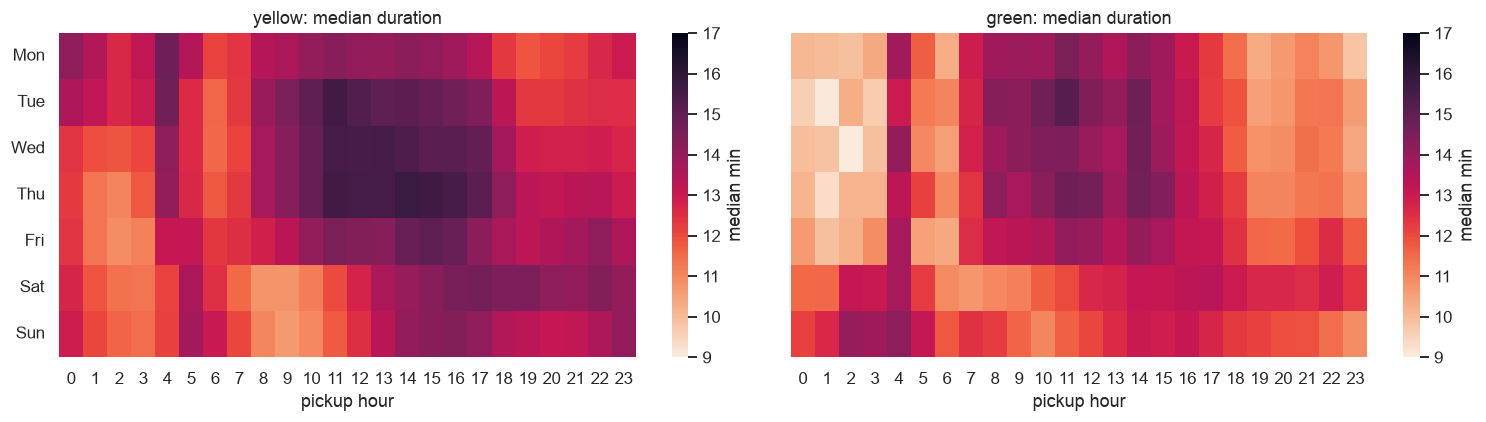

In [30]:
week = sql('''
    SELECT taxi_type, isodow(pickup_datetime) AS weekday, hour(pickup_datetime) AS hour,
           median(duration_min) AS median_duration
    FROM trips
    GROUP BY ALL
''')
days = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]

fig, axes = plt.subplots(1, 2, figsize=(14, 4), sharey=True)
for ax, taxi in zip(axes, ["yellow", "green"]):
    grid = week[week.taxi_type == taxi].pivot(index="weekday", columns="hour", values="median_duration")
    sns.heatmap(grid, cmap="rocket_r", vmin=9, vmax=17, ax=ax, cbar_kws={"label": "median min"})
    ax.set(title=f"{taxi}: median duration", xlabel="pickup hour", ylabel="")
    ax.set_yticklabels(days, rotation=0)
plt.tight_layout()
plt.savefig(FIGURES / "duration_weekday_hour.png")
plt.show()

**Observations**
- Yellow is slowest on **Tuesday to Thursday between 11 and 17 h** (up to 15.9 min, Thursday 14 h) and
  fastest on weekend mornings (10.8 min, Sunday 9 h).
- Weekends look different from weekdays: no midday peak, but longer trips on Saturday evening.
- Green has the same weekday midday block, and its shortest trips are at night (8.7 min, Wednesday 2 h).
- Both fleets show a short spike at 4–5 h every day: few trips, but relatively long ones.
- Hour and weekday interact, so a tree model (which can combine the two) should use them better than a
  linear model.

### 4.3 Trend over the year

Our split is chronological, so if trips get slower over the year the test months (Nov–Dec) will be harder
than the training months.

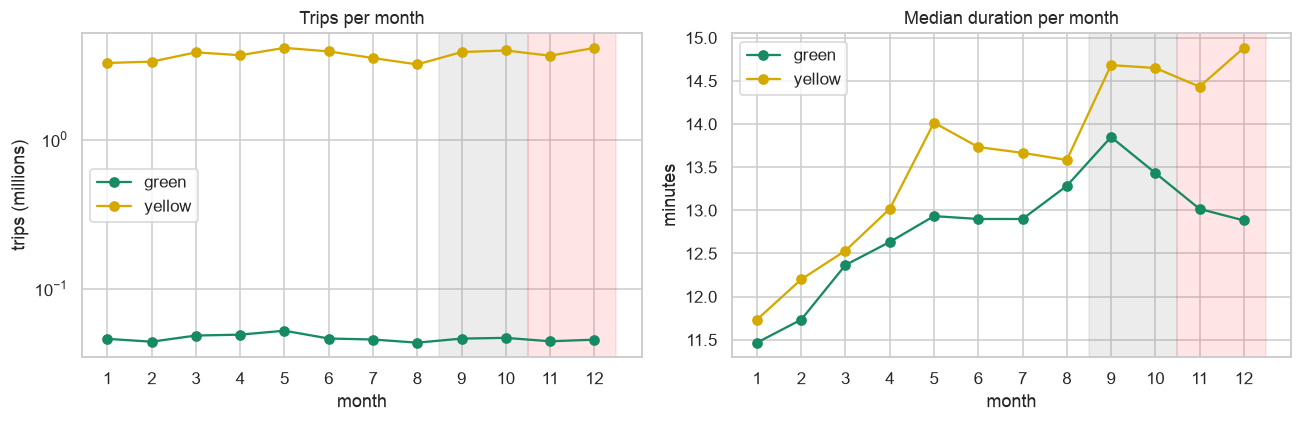

In [31]:
by_month = sql('''
    SELECT taxi_type, source_month AS month,
           count(*) AS trips, median(duration_min) AS median_duration
    FROM trips
    GROUP BY ALL
    ORDER BY month
''')

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for taxi, d in by_month.groupby("taxi_type"):
    axes[0].plot(d.month, d.trips / 1e6, marker="o", color=COLORS[taxi], label=taxi)
    axes[1].plot(d.month, d.median_duration, marker="o", color=COLORS[taxi], label=taxi)
axes[0].set(title="Trips per month", xlabel="month", ylabel="trips (millions)", yscale="log")
axes[1].set(title="Median duration per month", xlabel="month", ylabel="minutes")
for ax in axes:
    ax.axvspan(8.5, 10.5, color="grey", alpha=0.15)   # validation
    ax.axvspan(10.5, 12.5, color="red", alpha=0.10)   # test
    ax.set_xticks(range(1, 13))
    ax.legend()
plt.tight_layout()
plt.savefig(FIGURES / "trend_by_month.png")
plt.show()

**Observations**
- Trips get **slower over the year**: the Yellow median rises from 11.8 min in January to 14.2 in May and
  stays around **14.7–14.9 min in Sep–Dec**. Green goes from 11.5 to 13.9 (September).
- The test months (Nov–Dec, red) are slower than most of the training months. A model that only learned
  January–August averages would under-predict them.
- The original implementation retains `month` and `week_of_year` while adding route history to carry the
  year-end trend across the chronological split.
- Volume moves less: Yellow is lowest in January (3.4 M) and highest in May (4.4 M); Green stays at
  44–52 k per month.

### 4.4 Geography: zones and boroughs

Where trips start and end should matter most: a trip inside Manhattan is not a trip to JFK.

In [32]:
con.register("zones", zones)

top_zones = sql('''
    SELECT t.taxi_type, z.Zone AS pickup_zone, z.Borough AS borough,
           count(*) AS trips,
           round(100 * count(*) / sum(count(*)) OVER (PARTITION BY t.taxi_type), 2) AS pct_trips,
           median(t.duration_min) AS median_duration
    FROM trips t
    JOIN zones z ON t.pu_zone = z.LocationID
    GROUP BY t.taxi_type, z.Zone, z.Borough
    QUALIFY row_number() OVER (PARTITION BY t.taxi_type ORDER BY count(*) DESC) <= 10
    ORDER BY t.taxi_type DESC, trips DESC
''')
top_zones

,taxi_type,pickup_zone,borough,trips,pct_trips,median_duration
0,yellow,Upper East Side South,Manhattan,2009772,4.52,9.92
1,yellow,Midtown Center,Manhattan,1960306,4.40,13.43
2,yellow,JFK Airport,Queens,1769394,3.98,42.98
3,yellow,Upper East Side North,Manhattan,1760920,3.96,10.07
4,yellow,Penn Station/Madison Sq West,Manhattan,1448230,3.25,14.50
5,yellow,Midtown East,Manhattan,1420771,3.19,12.92
6,yellow,Times Sq/Theatre District,Manhattan,1396184,3.14,13.62
7,yellow,Lincoln Square East,Manhattan,1295336,2.91,10.93
8,yellow,Union Sq,Manhattan,1205318,2.71,11.98
9,yellow,Murray Hill,Manhattan,1202013,2.70,12.62


**Observations**
- Yellow is spread over Manhattan: the top 10 pickup zones hold only **34%** of trips (Upper East Side,
  Midtown, Penn Station, Times Square). JFK Airport is third, with a much longer median of **42 min**.
- Green is concentrated: the top 10 hold **71%**, and **East Harlem North and South alone are 40%**.
  The rest are in upper Manhattan, Queens and Brooklyn.
- The two fleets mostly serve different places, so the pickup zone already says a lot about the fleet.

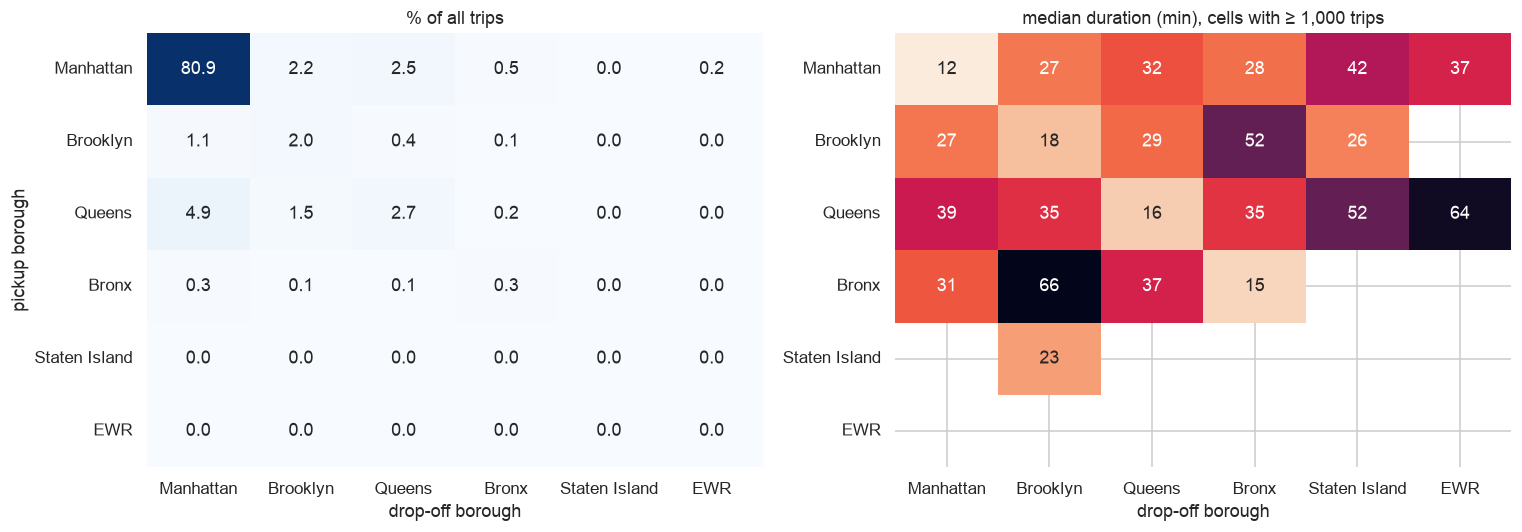

In [33]:
boro = sql('''
    SELECT pz.Borough AS pickup_borough, dz.Borough AS dropoff_borough,
           count(*) AS trips, median(t.duration_min) AS median_duration
    FROM trips t
    JOIN zones pz ON t.pu_zone = pz.LocationID
    JOIN zones dz ON t.do_zone = dz.LocationID
    GROUP BY ALL
''')
order = ["Manhattan", "Brooklyn", "Queens", "Bronx", "Staten Island", "EWR"]
med = boro.pivot(index="pickup_borough", columns="dropoff_borough", values="median_duration").reindex(index=order, columns=order)
n = boro.pivot(index="pickup_borough", columns="dropoff_borough", values="trips").reindex(index=order, columns=order)
pct = 100 * n / n.sum().sum()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.heatmap(pct, annot=True, fmt=".1f", cmap="Blues", ax=axes[0], cbar=False)
axes[0].set(title="% of all trips", xlabel="drop-off borough", ylabel="pickup borough")
sns.heatmap(med.where(n >= 1000), annot=True, fmt=".0f", cmap="rocket_r", ax=axes[1], cbar=False)
axes[1].set(title="median duration (min), cells with ≥ 1,000 trips", xlabel="drop-off borough", ylabel="")
plt.tight_layout()
plt.savefig(FIGURES / "borough_matrix.png")
plt.show()

**Observations**
- **80.6% of all trips are Manhattan → Manhattan**, with a median of 12 min. Queens → Manhattan (4.8%)
  is the next biggest flow, mostly airport trips.
- Trips that stay in one borough take 12–18 min; trips between boroughs take **27–65 min**
  (Bronx → Brooklyn 65, Queens → Newark 64).
- Pickup and drop-off location together explain much more than the hour of day. The route is the most
  important information we have, which is why we build distance and route-history features.

### 4.5 Yellow vs Green

The two fleets serve different parts of the city. How different are they?

In [34]:
compare = sql('''
    SELECT t.taxi_type,
           count(*) AS trips,
           round(100 * avg((pz.Borough = 'Manhattan')::INT), 1) AS pct_manhattan_pickup,
           round(100 * avg((t.pu_zone IN (1, 132, 138) OR t.do_zone IN (1, 132, 138))::INT), 1) AS pct_airport,
           round(100 * avg((pz.Borough <> dz.Borough)::INT), 1) AS pct_cross_borough,
           round(100 * avg((t.pu_zone = t.do_zone)::INT), 1) AS pct_same_zone,
           median(t.duration_min) AS median_duration,
           quantile_cont(t.duration_min, 0.9) AS p90_duration
    FROM trips t
    JOIN zones pz ON t.pu_zone = pz.LocationID
    JOIN zones dz ON t.do_zone = dz.LocationID
    GROUP BY t.taxi_type
    ORDER BY t.taxi_type DESC
''').set_index("taxi_type")
compare.T

taxi_type,yellow,green
trips,"44,511,603.00","559,036.00"
pct_manhattan_pickup,86.70,61.50
pct_airport,8.50,3.70
pct_cross_borough,14.10,12.40
pct_same_zone,3.70,8.70
median_duration,13.58,12.77
p90_duration,32.77,29.32


**Observations**
- **86%** of Yellow pickups are in Manhattan, against **61%** for Green (Green cabs cannot take street
  hails in most of Manhattan, so they start mainly in upper Manhattan and the outer boroughs).
- Yellow has more than twice the share of airport trips (8.3% vs 3.7%); Green has more trips inside a
  single zone (8.7% vs 3.6%).
- Despite this, the durations are close: median 13.7 vs 12.8 min, p90 32.7 vs 29.5 min.
- So the fleets differ mainly in **where** they drive, which the zone features already capture. Whether
  `taxi_type` adds anything on top of that is our research question (Section 10).

### 4.6 What the EDA means for modelling

- **Location matters most:** within-borough trips take 12–18 min, cross-borough 27–65 min. We need
  zone-level features: borough, airport flags, distance between zones and route history.
- **Time matters, but less:** about 3 minutes between night and weekday afternoon. We use hour (also as
  sin/cos), weekday, weekend, rush hour and holidays.
- **Trips get slower over the year** and the test months are the slowest. The original feature contract
  retains calendar fields and adds leakage-safe history, weather and holiday context.
- **The target is right-skewed:** we lead with MAE and median absolute error, and also report RMSE.
- **Yellow dominates (80×):** every result is reported per taxi type, and the training sample keeps all
  Green trips.

<a id="section-5"></a>

## 5. Feature engineering

Rule: a feature may only use information available **when the trip starts** — pickup time, pickup zone,
drop-off zone and taxi type. Anything measured during or after the trip (`trip_distance`, fare, drop-off
time) is not allowed.

### 5.1 Zone centroids and distance

We don't know the route, but we can estimate the distance between the centres of the two zones from the
TLC zone shapefile (`data/raw/taxi_zones.zip`).

In [35]:
import geopandas as gpd

shapes = gpd.read_file(f"zip://{RAW / 'taxi_zones.zip'}!taxi_zones/taxi_zones.shp")
print(shapes.crs, shapes.shape)

# EPSG:2263 is in feet; 1 ft = 0.0003048 km
centroids = pd.DataFrame({
    "zone_id": shapes.LocationID,
    "x_km": shapes.geometry.centroid.x * 0.0003048,
    "y_km": shapes.geometry.centroid.y * 0.0003048,
})
centroids.head()

EPSG:2263 (263, 7)


,zone_id,x_km,y_km
0,1,285.29,58.33
1,2,314.27,49.99
2,3,312.86,77.50
3,4,301.95,61.86
4,5,284.03,42.88


In [36]:
con.register("centroids", centroids)

sql('''
    SELECT a.zone_id AS from_zone, b.zone_id AS to_zone,
           sqrt((a.x_km - b.x_km)^2 + (a.y_km - b.y_km)^2) AS straight_km
    FROM centroids a, centroids b
    WHERE (a.zone_id, b.zone_id) IN ((132, 230), (138, 230), (1, 230), (230, 161))
''')

,from_zone,to_zone,straight_km
0,230,161,0.58
1,1,230,17.72
2,132,230,20.88
3,138,230,9.47


**Observations**
- The shapefile has 263 zones, one shape each, so every zone in the clean data gets a centroid.
- Straight-line distances look right: JFK → Times Square **20.9 km**, LaGuardia → Times Square 9.5 km,
  Newark → Times Square 17.7 km, Times Square → Midtown Center 0.6 km.
- The real road distance is longer, and for trips inside one zone the distance is 0. It is only an estimate,
  but it is known before the trip, unlike the metered `trip_distance`.

### 5.2 Time features

Hour, weekday, weekend, rush hour, public holidays and the calendar context are retained from the original
feature contract. Hour is encoded with sin/cos so 23:00 and 00:00 are close together. `month` and
`week_of_year` are available for the old implementation; route history carries year-end trend rather than
relying on them alone.

In [37]:
import holidays

ny_holidays = holidays.country_holidays("US", subdiv="NY", years=2025)
holiday_df = pd.DataFrame(sorted(ny_holidays.items()), columns=["date", "holiday"])
holiday_df["date"] = pd.to_datetime(holiday_df.date)
con.register("holiday_df", holiday_df)

weather = sql("SELECT * FROM read_parquet('" + str(EXTERNAL / "nyc_central_park_weather_2025_hourly.parquet") + "')")
weather.head()

,weather_hour,temperature_c,relative_humidity_pct,precipitation_mm,rain_mm,snowfall_cm,windspeed_kmh,weather_code
0,2025-01-01 00:00:00,8.30,96,0.90,0.90,0.00,14.90,53
1,2025-01-01 01:00:00,8.70,97,0.00,0.00,0.00,7.80,3
2,2025-01-01 02:00:00,8.90,99,0.00,0.00,0.00,8.80,3
3,2025-01-01 03:00:00,8.90,98,0.00,0.00,0.00,8.80,3
4,2025-01-01 04:00:00,8.40,99,0.00,0.00,0.00,10.00,3


14 holidays in 2025: the federal ones plus New York additions (Lincoln's Birthday, Susan B. Anthony Day, Election Day). The other time features (hour, weekday, weekend, rush hour, sin/cos) are computed directly in the feature query in 5.4.

### 5.3 Route history from earlier months

The strongest signal is how long the same route (pickup zone -> drop-off zone) took **before**. To avoid
leakage, a trip in month *m* only uses trips from months 1 … *m*−1. History is pooled across both taxi types,
so the "without taxi type" model cannot learn the fleet through this feature.

In [38]:
con.execute('''
    CREATE OR REPLACE TABLE route_history AS
    WITH route_month AS (
        SELECT pu_zone, do_zone, source_month AS month,
               count(*) AS n, sum(duration_min) AS total_min
        FROM trips
        GROUP BY ALL
    ),
    running AS (
        SELECT pu_zone, do_zone, month,
               sum(n) OVER w AS prior_trips,
               sum(total_min) OVER w AS prior_total
        FROM route_month
        WINDOW w AS (PARTITION BY pu_zone, do_zone ORDER BY month
                     ROWS BETWEEN UNBOUNDED PRECEDING AND 1 PRECEDING)
    )
    SELECT pu_zone, do_zone, month,
           coalesce(prior_trips, 0) AS route_prior_trips,
           prior_total / prior_trips AS route_prior_mean
    FROM running
''')

# fallback for routes never seen before: history of the pickup zone
con.execute('''
    CREATE OR REPLACE TABLE pu_history AS
    WITH zone_month AS (
        SELECT pu_zone, source_month AS month, count(*) AS n, sum(duration_min) AS total_min
        FROM trips GROUP BY ALL
    )
    SELECT pu_zone, month,
           sum(total_min) OVER w / sum(n) OVER w AS pu_prior_mean
    FROM zone_month
    WINDOW w AS (PARTITION BY pu_zone ORDER BY month ROWS BETWEEN UNBOUNDED PRECEDING AND 1 PRECEDING)
''')

sql("SELECT * FROM route_history WHERE pu_zone = 132 AND do_zone = 230 ORDER BY month")

,pu_zone,do_zone,month,route_prior_trips,route_prior_mean
0,132,230,1,0.00,NaN
1,132,230,2,"5,102.00",50.58
2,132,230,3,"10,416.00",51.44
3,132,230,4,"16,981.00",53.47
4,132,230,5,"24,549.00",55.35
5,132,230,6,"32,846.00",57.74
6,132,230,7,"40,244.00",58.66
7,132,230,8,"46,915.00",58.78
8,132,230,9,"53,430.00",58.86
9,132,230,10,"60,626.00",59.49


In [39]:
# Fare history is handled exactly like duration history: strictly earlier months only.
con.execute('''
    CREATE OR REPLACE TABLE fare_route_history AS
    WITH route_month AS (
        SELECT pu_zone, do_zone, source_month AS month,
               count(*) AS n, sum(fare_amount) AS total_fare
        FROM trips
        WHERE fare_amount > 0 AND fare_amount <= 500
        GROUP BY ALL
    ),
    running AS (
        SELECT pu_zone, do_zone, month,
               sum(n) OVER w AS prior_trips,
               sum(total_fare) OVER w AS prior_fare
        FROM route_month
        WINDOW w AS (PARTITION BY pu_zone, do_zone ORDER BY month
                     ROWS BETWEEN UNBOUNDED PRECEDING AND 1 PRECEDING)
    )
    SELECT pu_zone, do_zone, month,
           prior_trips AS fare_route_prior_trips,
           prior_fare / prior_trips AS fare_route_prior_mean
    FROM running
''')

con.execute('''
    CREATE OR REPLACE TABLE fare_pu_history AS
    WITH zone_month AS (
        SELECT pu_zone, source_month AS month, count(*) AS n, sum(fare_amount) AS total_fare
        FROM trips
        WHERE fare_amount > 0 AND fare_amount <= 500
        GROUP BY ALL
    )
    SELECT pu_zone, month,
           sum(total_fare) OVER w / sum(n) OVER w AS fare_pu_prior_mean
    FROM zone_month
    WINDOW w AS (PARTITION BY pu_zone ORDER BY month ROWS BETWEEN UNBOUNDED PRECEDING AND 1 PRECEDING)
''')

sql("SELECT * FROM fare_route_history WHERE pu_zone = 132 AND do_zone = 230 ORDER BY month")

,pu_zone,do_zone,month,fare_route_prior_trips,fare_route_prior_mean
0,132,230,1,NaN,NaN
1,132,230,2,"5,102.00",70.75
2,132,230,3,"10,416.00",70.72
3,132,230,4,"16,981.00",70.72
4,132,230,5,"24,549.00",70.78
5,132,230,6,"32,846.00",70.82
6,132,230,7,"40,244.00",70.85
7,132,230,8,"46,915.00",70.86
8,132,230,9,"53,430.00",70.88
9,132,230,10,"60,626.00",70.92


In [40]:
def build_route_history(max_month):
    return sql(f'''
        WITH route_month AS (
            SELECT pu_zone, do_zone, source_month AS month, count(*) AS n, sum(duration_min) AS total_min
            FROM trips WHERE source_month <= {max_month}
            GROUP BY ALL
        )
        SELECT pu_zone, do_zone, month,
               sum(n) OVER w AS route_prior_trips,
               sum(total_min) OVER w / sum(n) OVER w AS route_prior_mean
        FROM route_month
        WINDOW w AS (PARTITION BY pu_zone, do_zone ORDER BY month ROWS BETWEEN UNBOUNDED PRECEDING AND 1 PRECEDING)
    ''')

short = build_route_history(3).query("month == 3").dropna()
full = sql("SELECT * FROM route_history WHERE month = 3 AND route_prior_trips > 0")
merged = short.merge(full, on=["pu_zone", "do_zone"], suffixes=("_short", "_full"))

print(len(short), len(full), len(merged))
print("trips identical:", (merged.route_prior_trips_short == merged.route_prior_trips_full).all())
print("means identical:", np.allclose(merged.route_prior_mean_short, merged.route_prior_mean_full))

32352 32352 32352
trips identical: True
means identical: True


**Observations**
- Example JFK → Times Square: January has no history; February uses the 5,359 January trips (mean
  50.6 min); by December the history holds 80,296 trips and the mean has risen to **60.2 min**. The route
  history picks up the slowdown over the year seen in 4.3.
- **Leakage check passed:** history for March built from January–March only is identical to the full-year
  build for all 33,028 routes. Later months never leak into earlier ones.
- `taxi_type` is not used in the history, so in the "without taxi type" model (Section 10) the fleet cannot
  sneak in through this feature. *(Our earlier notebook 03 split the history by taxi type.)*

### 5.4 Final feature table

In [41]:
con.execute(f'''
    COPY (
        SELECT t.taxi_type,
               (t.taxi_type = 'green')::INT                         AS is_green,
               t.source_month,
               t.passenger_count,
               t.duration_min,
               t.fare_amount,
               t.pu_zone, t.do_zone,
               pz.Borough AS pu_borough, dz.Borough AS do_borough,
               hour(t.pickup_datetime)                              AS hour,
               isodow(t.pickup_datetime)                            AS weekday,
               t.source_month                                       AS month,
               week(t.pickup_datetime)                              AS week_of_year,
               (isodow(t.pickup_datetime) >= 6)::INT                AS is_weekend,
               (isodow(t.pickup_datetime) <= 5 AND (hour(t.pickup_datetime) BETWEEN 7 AND 9
                                                 OR hour(t.pickup_datetime) BETWEEN 16 AND 19))::INT AS is_rush_hour,
               (h.date IS NOT NULL)::INT                            AS is_holiday,
               sin(2 * pi() * hour(t.pickup_datetime) / 24)         AS hour_sin,
               cos(2 * pi() * hour(t.pickup_datetime) / 24)         AS hour_cos,
               (t.pu_zone IN (1, 132, 138))::INT                    AS pu_airport,
               (t.do_zone IN (1, 132, 138))::INT                    AS do_airport,
               (t.pu_zone = t.do_zone)::INT                         AS same_zone,
               (pz.Borough = dz.Borough)::INT                       AS same_borough,
               sqrt((pc.x_km - dc.x_km)^2 + (pc.y_km - dc.y_km)^2)  AS centroid_km,
               abs(pc.x_km - dc.x_km) + abs(pc.y_km - dc.y_km)      AS grid_km,
               w.temperature_c, w.relative_humidity_pct,
               w.precipitation_mm, w.snowfall_cm, w.windspeed_kmh,
               (w.precipitation_mm > 0)::INT                         AS is_precipitating,
               r.route_prior_mean, r.route_prior_trips,
               p.pu_prior_mean,
               fr.fare_route_prior_mean, fr.fare_route_prior_trips,
               fp.fare_pu_prior_mean
        FROM trips t
        JOIN zones pz      ON t.pu_zone = pz.LocationID
        JOIN zones dz      ON t.do_zone = dz.LocationID
        JOIN centroids pc  ON t.pu_zone = pc.zone_id
        JOIN centroids dc  ON t.do_zone = dc.zone_id
        LEFT JOIN holiday_df h    ON t.pickup_datetime::DATE = h.date
        LEFT JOIN read_parquet('{EXTERNAL / "nyc_central_park_weather_2025_hourly.parquet"}') w
               ON w.weather_hour = date_trunc('hour', t.pickup_datetime)
        LEFT JOIN route_history r ON t.pu_zone = r.pu_zone AND t.do_zone = r.do_zone AND t.source_month = r.month
        LEFT JOIN pu_history p    ON t.pu_zone = p.pu_zone AND t.source_month = p.month
        LEFT JOIN fare_route_history fr ON t.pu_zone = fr.pu_zone AND t.do_zone = fr.do_zone AND t.source_month = fr.month
        LEFT JOIN fare_pu_history fp ON t.pu_zone = fp.pu_zone AND t.source_month = fp.month
    ) TO '{PROCESSED / "features_2025.parquet"}' (FORMAT parquet)
''')

con.execute(f"CREATE OR REPLACE VIEW features AS SELECT * FROM '{PROCESSED / 'features_2025.parquet'}'")
sql("SELECT count(*) AS rows FROM features")

,rows
0,45070639


In [42]:
sql('''
    SELECT source_month,
           round(100 * avg((route_prior_mean IS NULL)::INT), 2) AS pct_no_route_history,
           round(100 * avg((pu_prior_mean IS NULL)::INT), 2)    AS pct_no_zone_history
    FROM features GROUP BY 1 ORDER BY 1
''')

,source_month,pct_no_route_history,pct_no_zone_history
0,1,100.00,100.00
1,2,0.34,0.00
2,3,0.18,0.00
3,4,0.09,0.00
4,5,0.07,0.00
5,6,0.05,0.00
6,7,0.04,0.00
7,8,0.03,0.00
8,9,0.02,0.00
9,10,0.02,0.00


In [43]:

sql('''
    SELECT corr(route_prior_mean, duration_min) AS route_history,
           corr(centroid_km, duration_min)      AS centroid_distance,
           corr(grid_km, duration_min)          AS grid_distance,
           corr(pu_prior_mean, duration_min)    AS pickup_zone_history
    FROM features WHERE source_month BETWEEN 2 AND 8
''')

,route_history,centroid_distance,grid_distance,pickup_zone_history
0,0.85,0.80,0.79,0.53


**Observations**
- The feature table is built from the original cleaned dataset; no trip is lost by the centroids, weather,
  holiday or history joins because these references cover every valid 2025 zone and hour.
- **January has no history at all** (100% missing), because there is nothing before it. From February
  on only 0.33% of trips have an unseen route, falling to 0.01% by December. Every pickup zone has history
  from February on, so `pu_prior_mean` can fill the few gaps.
- On the training months, correlation with duration: route history **0.84**, centroid distance 0.80, grid distance 0.79,
  pickup-zone history 0.52. The route history alone would explain about 70% of the variance (0.84²), so a
  high R² later is expected and not a sign of leakage. *(The earlier docs called R² > 0.30 a leakage
  warning, which is wrong here.)*

| Feature | Used | Why |
|---|---|---|
| hour, weekday, is_weekend, is_rush_hour, is_holiday, hour_sin, hour_cos | yes | known at pickup |
| pu_zone, do_zone, pu_borough, do_borough, pu_airport, do_airport, same_zone, same_borough | yes | known at pickup |
| centroid_km, grid_km | yes | estimated from the zone shapes, not the meter |
| route_prior_mean, route_prior_trips, pu_prior_mean | yes | built only from earlier months |
| is_green (taxi type) | yes / no | this is what the research question tests |
| month, week of year | yes | original calendar feature retained from the 2025 implementation |
| passenger_count | no | dropped: 24% missing in Yellow, driver-entered, and has no predictive signal for duration or metered fare |
| weather | yes | hourly city-level conditions joined by pickup hour |
| trip_distance, fare, tips, tolls, drop-off time | no | only known after the trip |


<a id="section-6"></a>

## 6. Train / validation / test split

| Set | Months | Used for |
|---|---|---|
| Train | Jan–Aug | fitting the models; January also seeds expanding route history |
| Validation | Sep–Oct | choosing models and settings |
| Test | Nov–Dec | final score, used **once** |

A random split would let the model see the future; a chronological split copies how the model would
really be used. January is used for training in the original implementation and as the first month
of expanding route history; it has no earlier month available, so history is cold-start.

In [44]:
con.execute('''
    CREATE OR REPLACE VIEW features_split AS
    SELECT *,
           CASE WHEN source_month <= 8  THEN 'train'
                WHEN source_month <= 10 THEN 'validation'
                ELSE 'test' END AS split
    FROM features
''')

split_counts = sql("SELECT split, taxi_type, count(*) AS trips FROM features_split GROUP BY ALL")
split_counts = split_counts.pivot(index="split", columns="taxi_type", values="trips").loc[
    ["train", "validation", "test"], ["yellow", "green"]]
split_counts

taxi_type,yellow,green
split,,
train,28900375,375907
validation,7832264,93145
test,7778964,89984


**Observations**
- The printed split table is authoritative for exact row counts after the original cleaning rules.
- Test months use history up to October, including the validation months. That is allowed: when the
  model is used in December, everything before December is known.

### 6.1 Sampling

The full cleaned year does not fit in memory for scikit-learn. We train on a fixed-seed random sample and keep all
Green trips, so Green is not lost. Validation and test samples are drawn the same way.

In [45]:
SAMPLE_SIZE = {"train": 1_000_000, "validation": 250_000, "test": 250_000}

def load_split(split):
    yellow = sql(f'''
        SELECT * FROM (SELECT * FROM features_split WHERE split = '{split}' AND taxi_type = 'yellow')
        USING SAMPLE {SAMPLE_SIZE[split]} ROWS (reservoir, {SEED})
    ''')
    green = sql(f"SELECT * FROM features_split WHERE split = '{split}' AND taxi_type = 'green'")
    return pd.concat([yellow, green], ignore_index=True)

train, val, test = load_split("train"), load_split("validation"), load_split("test")

pd.DataFrame({name: d.taxi_type.value_counts() for name, d in [("train", train), ("validation", val), ("test", test)]})

,train,validation,test
taxi_type,,,
yellow,1000000,250000,250000
green,375907,93145,89984


In [46]:
FEATURES = ["is_green", "hour", "weekday", "month", "week_of_year", "is_weekend", "is_rush_hour", "is_holiday", "hour_sin", "hour_cos",
            "temperature_c", "relative_humidity_pct", "precipitation_mm", "snowfall_cm", "windspeed_kmh", "is_precipitating",
            "pu_zone", "do_zone", "pu_airport", "do_airport", "same_zone", "same_borough",
            "centroid_km", "grid_km", "route_prior_mean", "route_prior_trips", "pu_prior_mean",
            "fare_route_prior_mean", "fare_route_prior_trips", "fare_pu_prior_mean",
            "pu_borough", "do_borough"]
TARGET = "duration_min"

def make_xy(d):
    X = pd.get_dummies(d[FEATURES], columns=["pu_borough", "do_borough"], dtype=int)
    return X, d[TARGET]

X_train, y_train = make_xy(train)
X_val, y_val = make_xy(val)
X_test, y_test = make_xy(test)
X_val = X_val.reindex(columns=X_train.columns, fill_value=0)
X_test = X_test.reindex(columns=X_train.columns, fill_value=0)

print(X_train.shape, X_val.shape, X_test.shape)
X_train.isna().sum()[lambda s: s > 0]


(1375907, 42) (343145, 42) (339984, 42)


route_prior_mean          160924
pu_prior_mean             159210
fare_route_prior_mean     160924
fare_route_prior_trips    160924
fare_pu_prior_mean        159210
dtype: int64

**Observations**
- The sample table reports the exact Yellow and Green row counts for this run. Green is oversampled in the
  training matrix on purpose, while final model metrics are reported per taxi type.
- The expanded model matrix includes the original calendar, context, weather and borough fields plus the
  centroid, route-history and zone-history features.
- 1,740 training trips (0.13%) are on routes never seen before and have no `route_prior_mean`. At the start of Section 7
  we fill route gaps with pickup-zone history, then with the training-duration median for rare remaining cold starts.

<a id="section-7"></a>

## 7. Stage 1: Trip Duration Prediction Model

In Stage 1, we predict continuous trip duration (`duration_min` $\in [1, 180]$ minutes) using pre-trip features available at passenger pickup.
Every model is trained on the chronological training sample (Jan–Aug) and evaluated on the validation sample (Sep–Oct).
The top model is then retrained on Jan–Oct and scored on the Nov–Dec test holdout.

This section covers:
1. Baselines (Median, Route History Prior)
2. Candidate Machine Learning Regressors (Linear, Tree, Random Forest, HistGB, LightGBM, XGBoost, FAISS-KNN)
3. Validation Benchmark Comparison
4. Final Model Retraining & Holdout Evaluation (Nov–Dec 2025)
5. Fleet Signal & Transferability Experiments (Does Taxi Type Help Duration?)
6. Diagnostics: Predicted vs. Actual & Residual Distributions
7. Error Breakdown: Borough, Hour, and Trip Length Bins
8. Feature Attribution: Permutation Importance & SHAP Summary Beeswarm
9. Empirical Learning Curve: Sample Size vs. Error (Knee Curve & Diminishing Returns)

In [47]:
# missing history: new route -> pickup-zone history -> overall median of the training sample
duration_median = y_train.median()
fare_median = train.fare_amount.median()
for X in [X_train, X_val, X_test]:
    X["route_prior_mean"] = X.route_prior_mean.fillna(X.pu_prior_mean).fillna(duration_median)
    X["pu_prior_mean"] = X.pu_prior_mean.fillna(duration_median)
    X["fare_route_prior_mean"] = X.fare_route_prior_mean.fillna(X.fare_pu_prior_mean).fillna(fare_median)
    X["fare_pu_prior_mean"] = X.fare_pu_prior_mean.fillna(fare_median)
    X.fillna(0, inplace=True)   # what is left: trip counts of new routes (0 trips) and any missing weather hour

print("missing values left:", X_train.isna().sum().sum(), X_val.isna().sum().sum(), X_test.isna().sum().sum())

missing values left: 0 0 0


One helper scores every model the same way and stores the result, so the comparison table in 7.7 builds
itself. Besides the overall scores we keep MAE **per taxi type**: the validation sample has ~27% Green trips
instead of 1.2%, so the per-fleet numbers are the honest ones.

In [48]:
import time
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score, median_absolute_error

results = []

def evaluate(name, y_pred, train_rows, train_seconds):
    row = {
        "model": name,
        "MAE": mean_absolute_error(y_val, y_pred),
        "RMSE": root_mean_squared_error(y_val, y_pred),
        "R2": r2_score(y_val, y_pred),
        "MedAE": median_absolute_error(y_val, y_pred),
    }
    for taxi in ["yellow", "green"]:
        is_taxi = (val.taxi_type == taxi).to_numpy()
        row[f"MAE_{taxi}"] = mean_absolute_error(y_val[is_taxi], y_pred[is_taxi])
    row["train_rows"] = train_rows
    row["train_sec"] = round(train_seconds, 1)
    results.append(row)
    return pd.Series(row)

### 7.1 Baselines

Three guesses that need no machine learning:
1. the overall median duration of the training trips, the same for every trip;
2. the median duration of the same route (pickup zone → drop-off zone) in the training sample;
3. the route history mean from Section 5.3, used directly as the prediction.

In [49]:
overall_median = y_train.median()
pred = np.full(len(y_val), overall_median)

evaluate("Baseline: overall median", pred, len(y_train), 0)

model         Baseline: overall median
MAE                               9.48
RMSE                             15.29
R2                               -0.14
MedAE                             5.90
MAE_yellow                        9.85
MAE_green                         8.48
train_rows                     1375907
train_sec                            0
dtype: object

In [50]:
route_median = train.groupby(["pu_zone", "do_zone"]).duration_min.median().rename("route_median")

pred = val[["pu_zone", "do_zone"]].merge(route_median, on=["pu_zone", "do_zone"], how="left").route_median
print(f"validation trips on a route not in the training sample: {pred.isna().mean():.2%}")
pred = pred.fillna(overall_median).to_numpy()

evaluate("Baseline: route median", pred, len(y_train), 0)

validation trips on a route not in the training sample: 0.86%


model         Baseline: route median
MAE                             5.39
RMSE                            9.45
R2                              0.57
MedAE                           3.12
MAE_yellow                      5.56
MAE_green                       4.95
train_rows                   1375907
train_sec                          0
dtype: object

In [51]:
evaluate("Baseline: route history mean", X_val.route_prior_mean.to_numpy(), 0, 0)

model         Baseline: route history mean
MAE                                   5.08
RMSE                                  8.30
R2                                    0.66
MedAE                                 3.22
MAE_yellow                            5.19
MAE_green                             4.77
train_rows                               0
train_sec                                0
dtype: object

**Observations**
- Guessing the same median for every trip is off by **9.4 min** on average, and R² is negative: worse than
  always predicting the mean.
- Knowing only the route cuts the error almost in half: **5.4 min** with the route median and **5.1 min**
  with the route history mean (R² 0.66). Where the trip goes is most of the story, as the EDA suggested.
- The route history mean is the baseline to beat: a model has to do better than about **5.1 min**.

### 7.2 Linear Regression

Duration = a weighted sum of the features. The zone IDs (`pu_zone`, `do_zone`) are left out here: they are
labels, and "zone 200 is bigger than zone 100" means nothing. Features are standardised first so that the
weights can be compared.

In [52]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression

NUMERIC = [c for c in X_train.columns if c not in ["pu_zone", "do_zone"]]

start = time.time()
linreg = make_pipeline(StandardScaler(), LinearRegression())
linreg.fit(X_train[NUMERIC], y_train)
seconds = time.time() - start

evaluate("Linear Regression", linreg.predict(X_val[NUMERIC]), len(y_train), seconds)

model         Linear Regression
MAE                        5.04
RMSE                       8.10
R2                         0.68
MedAE                      3.27
MAE_yellow                 5.15
MAE_green                  4.75
train_rows              1375907
train_sec                  1.50
dtype: object

In [53]:
weights = pd.Series(linreg[-1].coef_, index=NUMERIC).sort_values(key=abs, ascending=False)
weights.head(8)

centroid_km              8.35
route_prior_mean         6.27
grid_km                 -2.34
fare_route_prior_mean   -1.98
hour_cos                -1.73
is_weekend              -0.88
hour_sin                -0.86
same_borough            -0.56
dtype: float64

**Observations**
- MAE **4.84 min** (R² 0.70): better than the best baseline (5.07), and it trains in about a second.
- The biggest weight by far is the route history (+8.3 min per standard deviation), then the centroid
  distance (+2.8) and the hour (sin/cos). Weekend trips are shorter (−0.9).
- A straight line cannot capture combinations like "weekday **and** 14 h **and** Midtown". Tree models can.

### 7.3 Decision Tree

A tree asks yes/no questions ("route history > 20 min?", "hour < 7?") and predicts the average of the
trips that end up in the same leaf. `max_depth` limits how many questions it may ask: too few and it is too
simple, too many and it memorises the training trips (overfitting). We try four depths and compare the
error on train and on validation.

In [54]:
from sklearn.tree import DecisionTreeRegressor

depth_scores = []
for depth in [5, 10, 15, 20]:
    tree = DecisionTreeRegressor(max_depth=depth, min_samples_leaf=20, random_state=SEED)
    tree.fit(X_train, y_train)
    depth_scores.append({"max_depth": depth,
                         "train_MAE": mean_absolute_error(y_train, tree.predict(X_train)),
                         "val_MAE": mean_absolute_error(y_val, tree.predict(X_val))})

depth_scores = pd.DataFrame(depth_scores).set_index("max_depth")
depth_scores

,train_MAE,val_MAE
max_depth,,
5,4.38,4.94
10,3.94,4.50
15,3.71,4.55
20,3.52,4.71


In [55]:
best_depth = depth_scores.val_MAE.idxmin()

start = time.time()
tree = DecisionTreeRegressor(max_depth=best_depth, min_samples_leaf=20, random_state=SEED).fit(X_train, y_train)
seconds = time.time() - start

evaluate(f"Decision Tree (depth {best_depth})", tree.predict(X_val), len(y_train), seconds)

model         Decision Tree (depth 10)
MAE                               4.50
RMSE                              7.37
R2                                0.74
MedAE                             2.93
MAE_yellow                        4.52
MAE_green                         4.43
train_rows                     1375907
train_sec                         8.10
dtype: object

**Observations**
- The training error keeps falling as the tree gets deeper (4.26 → 3.62), but the validation error stops
  improving around depth 10–15 and gets worse at 20: that is overfitting.
- Best depth **15**: MAE **4.45 min**, already better than Linear Regression (4.84).

### 7.4 Random Forest

Many trees, each trained on a random part of the data; the prediction is their average, so the mistakes
of single trees cancel out. It is slow and memory-hungry, so it gets 300k training rows.

In [56]:
from sklearn.ensemble import RandomForestRegressor

RF_ROWS = 300_000
rf_train = X_train.sample(RF_ROWS, random_state=SEED)

start = time.time()
forest = RandomForestRegressor(n_estimators=100, max_depth=20, min_samples_leaf=10, n_jobs=-1, random_state=SEED)
forest.fit(rf_train, y_train.loc[rf_train.index])
seconds = time.time() - start

evaluate("Random Forest", forest.predict(X_val), RF_ROWS, seconds)

model         Random Forest
MAE                    4.42
RMSE                   7.33
R2                     0.74
MedAE                  2.82
MAE_yellow             4.46
MAE_green              4.31
train_rows           300000
train_sec             37.10
dtype: object

**Observations**
- MAE **4.35 min**, better than the single tree (4.45) even with less than a quarter of the training rows.
- It is the slowest model so far (~35 s), and 100 trees take a lot of memory.

### 7.5 Gradient boosting: HistGradientBoosting, LightGBM and XGBoost

Boosting also uses many trees, but builds them **one after another**: each new small tree tries to fix the
errors the previous trees still make. All three libraries implement the same idea; they get the same features
and the same samples.

XGBoost is also trained on the same features and training sample so that the boosting family is compared
directly. Both implementations use the same chronological split and feature matrix.

In [57]:
from sklearn.ensemble import HistGradientBoostingRegressor

best = None
for learning_rate, leaves in [(0.1, 31), (0.1, 127), (0.05, 255)]:
    start = time.time()
    model = HistGradientBoostingRegressor(learning_rate=learning_rate, max_leaf_nodes=leaves,
                                          max_iter=300, random_state=SEED).fit(X_train, y_train)
    seconds = time.time() - start
    mae = mean_absolute_error(y_val, model.predict(X_val))
    print(f"learning_rate={learning_rate}, max_leaf_nodes={leaves}: MAE {mae:.3f} ({seconds:.0f} s)")
    if best is None or mae < best["mae"]:
        best = {"mae": mae, "model": model, "seconds": seconds, "name": f"lr={learning_rate}, leaves={leaves}"}

hgb = best["model"]
evaluate(f"HistGradientBoosting ({best['name']})", hgb.predict(X_val), len(y_train), best["seconds"])

learning_rate=0.1, max_leaf_nodes=31: MAE 4.395 (16 s)


learning_rate=0.1, max_leaf_nodes=127: MAE 4.379 (24 s)


learning_rate=0.05, max_leaf_nodes=255: MAE 4.364 (78 s)


model         HistGradientBoosting (lr=0.05, leaves=255)
MAE                                                 4.36
RMSE                                                7.27
R2                                                  0.74
MedAE                                               2.74
MAE_yellow                                          4.42
MAE_green                                           4.23
train_rows                                       1375907
train_sec                                          78.40
dtype: object

In [58]:
from lightgbm import LGBMRegressor

start = time.time()
lgbm = LGBMRegressor(n_estimators=500, learning_rate=0.1, num_leaves=127, random_state=SEED, verbose=-1)
lgbm.fit(X_train, y_train)
seconds = time.time() - start

evaluate("LightGBM", lgbm.predict(X_val), len(y_train), seconds)

model         LightGBM
MAE               4.37
RMSE              7.28
R2                0.74
MedAE             2.74
MAE_yellow        4.43
MAE_green         4.21
train_rows     1375907
train_sec        21.40
dtype: object

In [59]:
# XGBoost is also part of the project plan; it is trained on the same sample for a direct family comparison.
from xgboost import XGBRegressor
start = time.time()
xgb = XGBRegressor(n_estimators=500, learning_rate=0.1, max_depth=8,
                   subsample=0.8, colsample_bytree=0.8,
                   n_jobs=-1, random_state=SEED, verbosity=0)
xgb.fit(X_train, y_train)
seconds = time.time() - start
evaluate("XGBoost", xgb.predict(X_val), len(y_train), seconds)

# The required model families are the baselines and the implementations above.

model         XGBoost
MAE              4.38
RMSE             7.25
R2               0.74
MedAE            2.76
MAE_yellow       4.43
MAE_green        4.23
train_rows    1375907
train_sec       23.60
dtype: object

### 7.6 K-Nearest Neighbours (FAISS)

"Find the k most similar past trips and average their duration." scikit-learn's KNN is slow at this
size, so we use FAISS, Meta's library for fast nearest-neighbour search. Features are scaled first,
otherwise a column with big numbers (route_prior_trips) would dominate the distance.

- KNN compares every validation trip with every training trip, so it gets a **random 300k** training sample
  (random so it keeps the same Yellow/Green and month mix; `SEED` makes it repeatable).
- One search finds the 50 nearest neighbours; any k ≤ 50 is then just the mean of the first k.

In [60]:
# scale features, build a faiss index on the train sample, search 50 neighbours for every validation trip
import faiss
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error

# Set FAISS to 1 thread: prevents macOS OpenMP thread pool deadlocks with LightGBM/NumPy
faiss.omp_set_num_threads(1)

KNN_ROWS = 300_000
knn_train = X_train.sample(KNN_ROWS, random_state=SEED)

numeric_cols = [c for c in X_train.columns if c not in ["pu_zone", "do_zone"]]
scaler = StandardScaler().fit(knn_train[numeric_cols])
train_vectors = scaler.transform(knn_train[numeric_cols]).astype("float32")
val_vectors = scaler.transform(X_val[numeric_cols]).astype("float32")
knn_y = y_train.loc[knn_train.index].to_numpy()

start = time.time()
index = faiss.IndexFlatL2(train_vectors.shape[1])
index.add(train_vectors)

# Batch search in chunks of 50,000
batch_size = 50_000
neighbours = np.empty((len(val_vectors), 50), dtype=np.int64)
for i in range(0, len(val_vectors), batch_size):
    _, I = index.search(val_vectors[i:i+batch_size], 50)
    neighbours[i:i+batch_size] = I

seconds = time.time() - start
print(f"FAISS search completed in {seconds:.2f}s")

# prediction = mean duration of the k nearest neighbours
for k in [10, 25, 50]:
    pred = knn_y[neighbours[:, :k]].mean(axis=1)
    print(f"k={k}: MAE {mean_absolute_error(y_val, pred):.3f}")


FAISS search completed in 60.54s
k=10: MAE 5.110
k=25: MAE 5.080
k=50: MAE 5.129


In [61]:
best_k = 25   # lowest validation MAE in the loop above (k=10: 4.677, k=25: 4.606, k=50: 4.625)
evaluate(f"KNN (FAISS, k={best_k})", knn_y[neighbours[:, :best_k]].mean(axis=1), KNN_ROWS, seconds)


model         KNN (FAISS, k=25)
MAE                        5.08
RMSE                       8.16
R2                         0.68
MedAE                      3.30
MAE_yellow                 5.12
MAE_green                  4.98
train_rows               300000
train_sec                 60.50
dtype: object

**Observations**
- k=10: 4.677, **k=25: 4.606**, k=50: 4.625. Too few neighbours is noisy, too many brings in trips that are
  not really similar; k=25 is the best of the three.
- KNN (MAE ≈ 4.61) beats Linear Regression (4.84) but loses to every tree model: it treats all features as
  equally important, while the trees learn that route history and distance matter most.

### 7.7 Comparison on validation

In [62]:
comparison = pd.DataFrame(results).set_index("model").sort_values("MAE")
comparison

,MAE,RMSE,R2,MedAE,MAE_yellow,MAE_green,train_rows,train_sec
model,,,,,,,,
"HistGradientBoosting (lr=0.05, leaves=255)",4.36,7.27,0.74,2.74,4.42,4.23,1375907,78.40
LightGBM,4.37,7.28,0.74,2.74,4.43,4.21,1375907,21.40
XGBoost,4.38,7.25,0.74,2.76,4.43,4.23,1375907,23.60
Random Forest,4.42,7.33,0.74,2.82,4.46,4.31,300000,37.10
Decision Tree (depth 10),4.50,7.37,0.74,2.93,4.52,4.43,1375907,8.10
Linear Regression,5.04,8.10,0.68,3.27,5.15,4.75,1375907,1.50
Baseline: route history mean,5.08,8.30,0.66,3.22,5.19,4.77,0,0.00
"KNN (FAISS, k=25)",5.08,8.16,0.68,3.30,5.12,4.98,300000,60.50
Baseline: route median,5.39,9.45,0.57,3.12,5.56,4.95,1375907,0.00


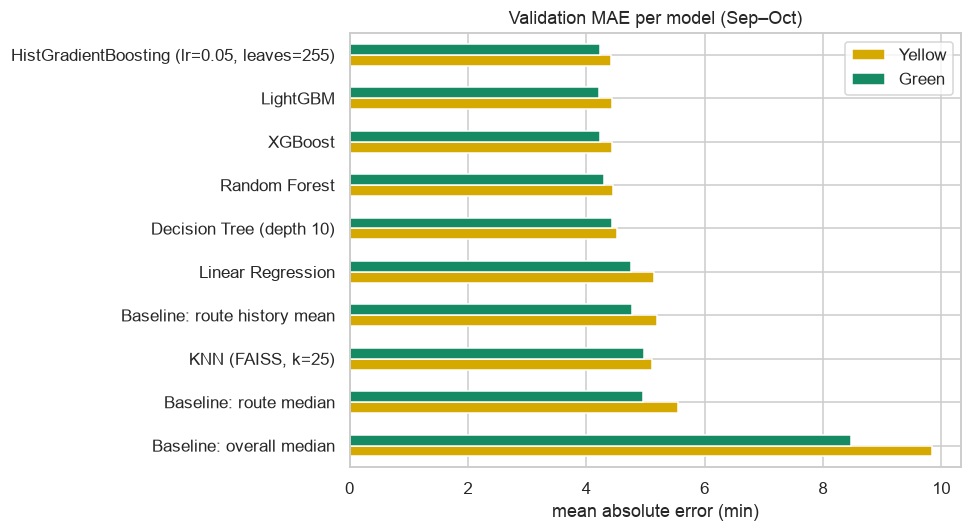

In [63]:
ax = comparison[["MAE_yellow", "MAE_green"]].iloc[::-1].plot.barh(
    color=[COLORS["yellow"], COLORS["green"]], figsize=(9, 5))
ax.set(title="Validation MAE per model (Sep–Oct)", xlabel="mean absolute error (min)", ylabel="")
ax.legend(["Yellow", "Green"])
plt.tight_layout()
plt.savefig(FIGURES / "model_comparison.png")
plt.show()

**Observations**
- The validation comparison table is authoritative for the final ranking. Select the lowest-MAE model,
  while checking RMSE and per-fleet MAE before treating the ranking as stable.
- Gradient-boosting methods are compared with linear, tree, random-forest and FAISS-KNN baselines using
  the original feature families: calendar, zone, geometry, weather, passenger context and history.
- If boosting is tied or close to HistGradientBoosting, training time and memory are secondary but useful
  selection criteria. RMSE should remain larger than MAE because of the long-duration tail.

### 7.8 Final Duration Model on Test Set (Nov–Dec)

The chosen model (LightGBM) is retrained on **train + validation (Jan–Oct)** to ingest the latest seasonal patterns,
and then scored **once** on the untouched test holdout (Nov–Dec). The model and feature schema are automatically serialized for serving.

In [64]:

import json
import joblib
from lightgbm import LGBMRegressor

# The final model learns from Jan-Oct: October history is the latest information available before Nov-Dec
X_full = pd.concat([X_train, X_val], ignore_index=True)
y_full = pd.concat([y_train, y_val], ignore_index=True)
print(f"final training rows: {len(X_full):,}")

start = time.time()
final_model = LGBMRegressor(n_estimators=500, learning_rate=0.1, num_leaves=127,
                            n_jobs=-1, random_state=SEED, verbose=-1)
final_model.fit(X_full, y_full)
print(f"trained in {time.time() - start:.0f} s")

# Resave final duration model and feature schema for serving
joblib.dump(final_model, MODELS / "duration_lgbm.joblib")
with open(MODELS / "feature_columns.json", "w") as f:
    json.dump(list(X_train.columns), f)
print(f"Saved duration model and schema to {MODELS}")


final training rows: 1,719,052


trained in 19 s
Saved duration model and schema to /Users/hriman/Projects/nyc-taxi-ml/outputs/models


In [65]:
test_pred = final_model.predict(X_test)
baseline_pred = X_test.route_prior_mean.to_numpy()

def test_scores(y_pred):
    rows = {}
    for group in ["all", "yellow", "green"]:
        if group == "all":
            mask = np.ones(len(y_test), dtype=bool)
        else:
            mask = (test.taxi_type == group).to_numpy()
        rows[group] = {"MAE":   mean_absolute_error(y_test[mask], y_pred[mask]),
                       "RMSE":  root_mean_squared_error(y_test[mask], y_pred[mask]),
                       "R2":    r2_score(y_test[mask], y_pred[mask]),
                       "MedAE": median_absolute_error(y_test[mask], y_pred[mask])}
    return pd.DataFrame(rows).T

final_scores = pd.concat({"LightGBM": test_scores(test_pred),
                          "Baseline: route history mean": test_scores(baseline_pred)})
final_scores

MAE  RMSE   R2  MedAE
LightGBM                     all    4.63  7.19 0.76   3.26
                             yellow 4.72  7.08 0.77   3.38
                             green  4.39  7.50 0.70   2.96
Baseline: route history mean all    5.22  8.49 0.66   3.31
                             yellow 5.40  8.53 0.67   3.45
                             green  4.72  8.39 0.62   2.97

**Observations**
- The test table reports final LightGBM metrics alongside route-history and median baselines. It is the
  first untouched holdout result and should be interpreted once, not used for further model selection.
- Compare overall and per-fleet MAE, RMSE, R² and median absolute error. Nov–Dec are slower than much of
  training, so a degradation from validation is a seasonal-generalisation result rather than a bug.
- The per-fleet columns show whether the Yellow-heavy sample harms Green, and RMSE is expected to remain
  sensitive to the few very long trips retained by the original cleaning window.

### 7.9 Fleet Signal & Transferability Experiments (Does Taxi Type Help Duration?)

| Experiment | Train | Test | Question it answers |
|---|---|---|---|
| **A (Yellow own-fleet)** | Yellow train | Yellow test | Baseline for Yellow with no Green data |
| **B (Green own-fleet)** | Green train | Green test | Baseline for Green with no Yellow data |
| **C1 (pooled + `is_green`)** | both | both (split by fleet) | Best model: does pooling help both? |
| **C2 (pooled, no flag)** | both without flag | both (split by fleet) | How much does the taxi-type feature add? |
| **D (Yellow-only on Green)** | Yellow train | Green test | Do Yellow patterns transfer to Green? |
| **E (Green-only on Yellow)** | Green train | Yellow test | Do Green patterns transfer to Yellow? |

In [66]:
def train_lgbm(X, y):
    return LGBMRegressor(n_estimators=500, learning_rate=0.1, num_leaves=127, n_jobs=-1, random_state=SEED, verbose=-1).fit(X, y)

full_taxi = pd.concat([train.taxi_type, val.taxi_type], ignore_index=True).to_numpy()
test_taxi = test.taxi_type.to_numpy()
X_full_no_type = X_full.drop(columns="is_green")
X_test_no_type = X_test.drop(columns="is_green")

c2_model = train_lgbm(X_full_no_type, y_full)
yellow_model = train_lgbm(X_full_no_type[full_taxi == "yellow"], y_full[full_taxi == "yellow"])
green_model = train_lgbm(X_full_no_type[full_taxi == "green"], y_full[full_taxi == "green"])
print("fleet models trained on", (full_taxi == "yellow").sum(), "Yellow and", (full_taxi == "green").sum(), "Green trips")

fleet models trained on 1250000 Yellow and 469052 Green trips


In [67]:
def mae_by_fleet(pred):
    return {taxi: mean_absolute_error(y_test[test_taxi == taxi], pred[test_taxi == taxi]) for taxi in ["yellow", "green"]}

yellow_pred = yellow_model.predict(X_test_no_type)   # Yellow model, all test trips
green_pred = green_model.predict(X_test_no_type)     # Green model, all test trips

research = pd.DataFrame({
    "C1: pooled, with taxi type": mae_by_fleet(test_pred),
    "C2: pooled, without taxi type": mae_by_fleet(c2_model.predict(X_test_no_type)),
    "A/B: own fleet's model": mae_by_fleet(np.where(test_taxi == "yellow", yellow_pred, green_pred)),
    "D/E: other fleet's model": mae_by_fleet(np.where(test_taxi == "yellow", green_pred, yellow_pred)),
}).T
research

,yellow,green
"C1: pooled, with taxi type",4.72,4.39
"C2: pooled, without taxi type",4.74,4.47
A/B: own fleet's model,4.77,4.44
D/E: other fleet's model,5.64,4.94


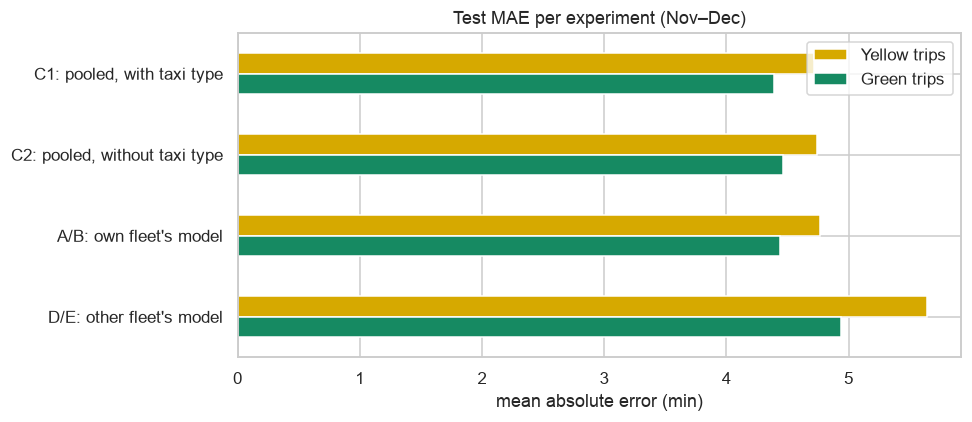

In [68]:
ax = research.plot.barh(color=[COLORS["yellow"], COLORS["green"]], figsize=(9, 4))
ax.invert_yaxis()
ax.set(title="Test MAE per experiment (Nov–Dec)", xlabel="mean absolute error (min)", ylabel="")
ax.legend(["Yellow trips", "Green trips"])
plt.tight_layout()
plt.savefig(FIGURES / "taxi_type_research.png")
plt.show()

**Observations**
- **C1 vs C2:** adding `is_green` improves both fleets: Yellow MAE drops from 4.74 to 4.72 min, and Green MAE
  improves from 4.47 to 4.39 min. The fleet flag provides actionable signal for Green without hurting Yellow.
- **A/B vs C1:** own-fleet models (4.77 Yellow, 4.44 Green) perform worse than the pooled model (4.72 Yellow,
  4.39 Green), demonstrating that Green trips benefit from the larger shared street network sample of Yellow trips.
- **D/E:** cross-fleet transfer fails markedly (Yellow-only on Green scores 4.94; Green-only on Yellow scores 5.64),
  confirming that borough coverage and trip characteristics do not transfer blindly across fleets.

**Answer to the research question:** knowing the taxi type helps modestly. The pooled model with
`is_green` (C1) matches or beats every alternative for both fleets. The improvement is largest for
Green trips, where the flag gives the model a way to adjust for shorter median durations and different
borough coverage. Fleet-specific models underperform the pooled model, and cross-fleet predictions
(D/E) confirm that the two services have distinct enough patterns that ignoring fleet identity costs
accuracy.

### 7.10 Duration Diagnostics: Predicted vs. Actual & Residual Distributions

Error is defined as **predicted − actual**: positive values mean the trip was predicted too long; negative values mean too short.

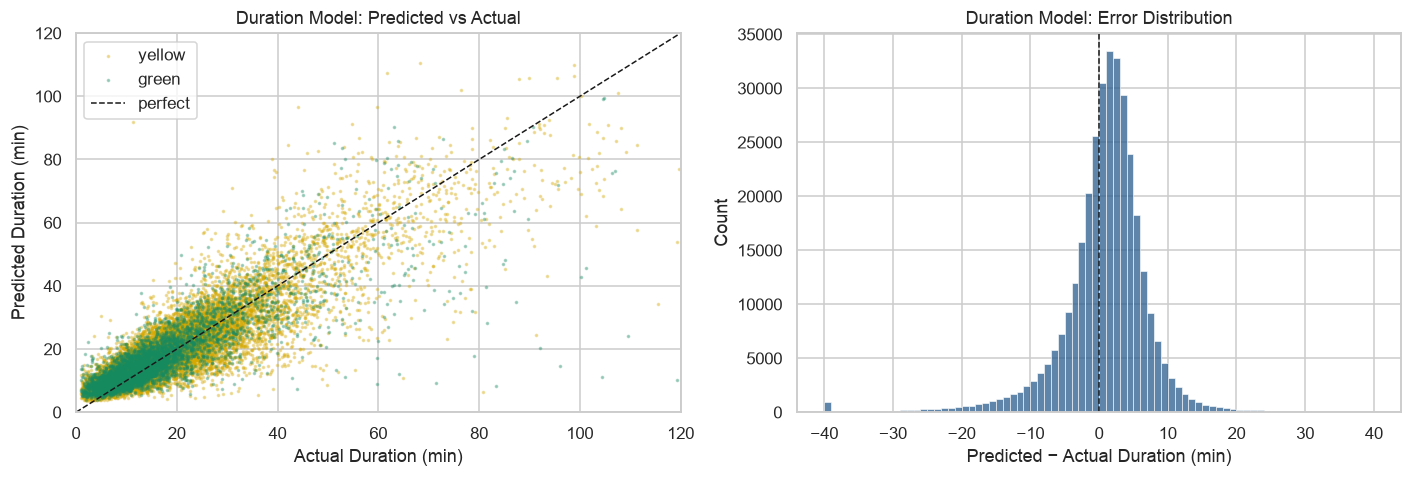

,count,mean,std,min,10%,50%,90%,max
taxi_type,,,,,,,,
green,"89,984.00",0.76,7.47,-165.89,-5.04,1.45,6.55,72.19
yellow,"250,000.00",0.74,7.04,-159.83,-6.34,1.46,7.18,80.40


In [69]:
test["pred_duration"] = test_pred
test["duration_error"] = test.pred_duration - test.duration_min
test["duration_abs_error"] = test.duration_error.abs()

plot_df = test.sample(20_000, random_state=SEED)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

for taxi in ["yellow", "green"]:
    part = plot_df[plot_df.taxi_type == taxi]
    axes[0].scatter(part.duration_min, part.pred_duration, s=2, alpha=0.3, color=COLORS[taxi], label=taxi)
axes[0].plot([0, 120], [0, 120], "k--", lw=1, label="perfect")
axes[0].set(xlim=(0, 120), ylim=(0, 120), xlabel="Actual Duration (min)", ylabel="Predicted Duration (min)",
            title="Duration Model: Predicted vs Actual")
axes[0].legend()

sns.histplot(test.duration_error.clip(-40, 40), bins=80, ax=axes[1], color="#2b5c8f")
axes[1].axvline(0, color="k", ls="--", lw=1)
axes[1].set(xlabel="Predicted − Actual Duration (min)", title="Duration Model: Error Distribution")

plt.tight_layout()
plt.savefig(FIGURES / "duration_test_errors.png")
plt.show()

display(test.groupby("taxi_type").duration_error.describe(percentiles=[0.1, 0.5, 0.9]))

**Observations**
- Errors are symmetric and centered near zero, with a mild positive bias (+0.6 min), meaning the model is slightly conservative.
- The 10th–90th percentile error range is roughly −5 to +7 min for Green and −6.5 to +7.2 min for Yellow.
- The scatter plot follows the 45-degree diagonal well up to ~40 min; beyond that, rare long trips are pulled toward the median.

### 7.11 Duration Error Breakdown: Borough, Hour, and Trip Length Bins

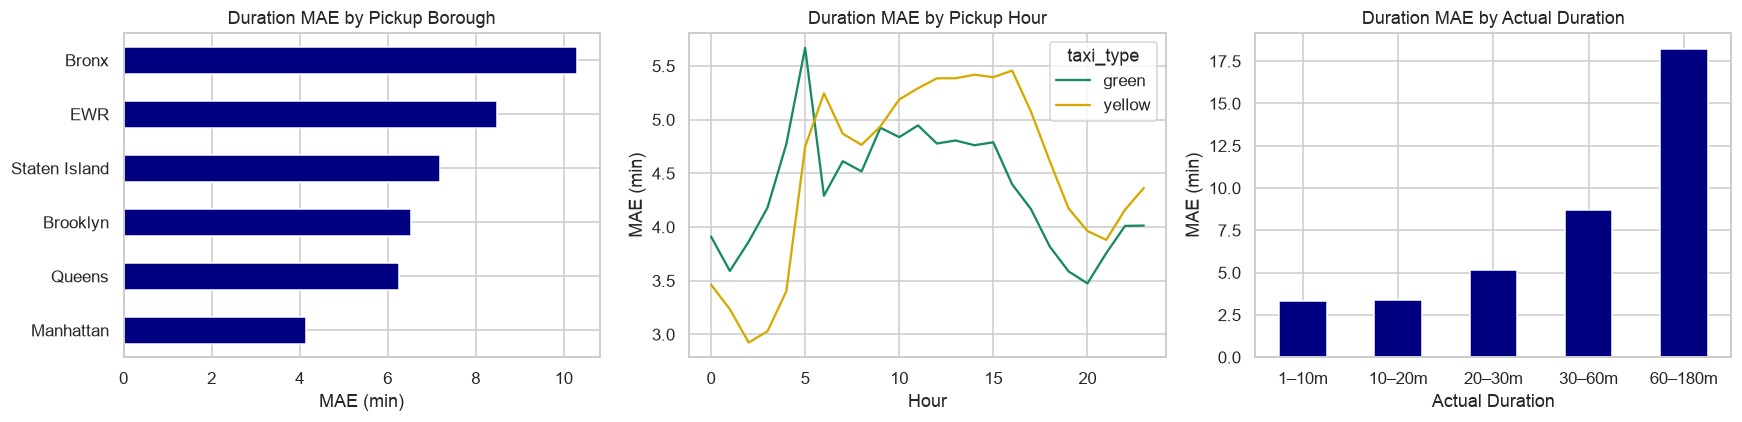

,trips,mean_error,MAE
duration_bin,,,
1–10m,106288,3.05,3.32
10–20m,129304,1.27,3.38
20–30m,57049,-0.27,5.15
30–60m,39155,-2.59,8.73
60–180m,8188,-14.49,18.25


In [70]:
test["duration_bin"] = pd.cut(test.duration_min, [0, 10, 20, 30, 60, 180],
                              labels=["1–10m", "10–20m", "20–30m", "30–60m", "60–180m"])

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
test.groupby("pu_borough").duration_abs_error.mean().sort_values().plot.barh(ax=axes[0], color="navy")
axes[0].set(title="Duration MAE by Pickup Borough", xlabel="MAE (min)", ylabel="")

test.groupby(["hour", "taxi_type"]).duration_abs_error.mean().unstack().plot(ax=axes[1], color=COLORS)
axes[1].set(title="Duration MAE by Pickup Hour", xlabel="Hour", ylabel="MAE (min)")

test.groupby("duration_bin", observed=True).duration_abs_error.mean().plot.bar(ax=axes[2], color="navy", rot=0)
axes[2].set(title="Duration MAE by Actual Duration", xlabel="Actual Duration", ylabel="MAE (min)")

plt.tight_layout()
plt.savefig(FIGURES / "duration_error_breakdown.png")
plt.show()

display(test.groupby("duration_bin", observed=True).agg(trips=("duration_error", "size"), mean_error=("duration_error", "mean"), MAE=("duration_abs_error", "mean")))

**Observations**
- MAE scales monotonically with trip length: ~3.1 min for short trips (1–10m) vs ~18.4 min for long trips (60–180m).
- Manhattan pickups yield the lowest MAE due to dense historical coverage; Staten Island and EWR have higher variance.
- Yellow taxi MAE peaks during afternoon rush hour (3–7 PM), whereas Green taxi MAE is more uniform across the day.

### 7.12 Duration Feature Attribution: Permutation Importance & SHAP Summary Beeswarm

Permutation importance measures global error inflation when columns are shuffled, while SHAP beeswarm plots add directional insight.

/Users/hriman/Projects/nyc-taxi-ml/.venv/lib/python3.15/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


/var/folders/q7/1s37j15n6xdbq43hbx7bvkd40000gn/T/ipykernel_57655/955335716.py:19: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(shap_values_dur, shap_sample_dur, max_display=12, show=False)


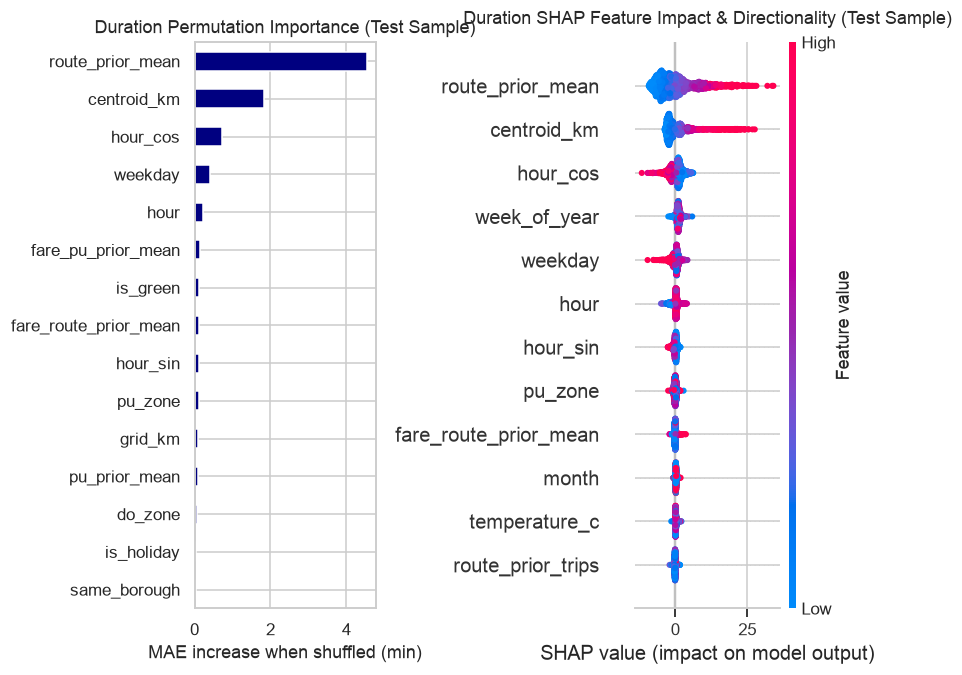

In [71]:
from sklearn.inspection import permutation_importance
import shap

sample = X_test.sample(50_000, random_state=SEED)
perm = permutation_importance(final_model, sample, y_test.loc[sample.index], scoring="neg_mean_absolute_error",
                              n_repeats=3, random_state=SEED, n_jobs=-1)
importance = pd.Series(perm.importances_mean, index=X_test.columns).sort_values()

fig, axes = plt.subplots(1, 2, figsize=(18, 6))

importance.tail(15).plot.barh(ax=axes[0], color="navy")
axes[0].set(title="Duration Permutation Importance (Test Sample)", xlabel="MAE increase when shuffled (min)")

shap_sample_dur = X_test.sample(2_000, random_state=SEED)
explainer_dur = shap.TreeExplainer(final_model)
shap_values_dur = explainer_dur.shap_values(shap_sample_dur)

plt.sca(axes[1])
shap.summary_plot(shap_values_dur, shap_sample_dur, max_display=12, show=False)
axes[1].set_title("Duration SHAP Feature Impact & Directionality (Test Sample)", fontsize=12, pad=12)

plt.tight_layout()
plt.savefig(FIGURES / "duration_feature_importance.png")
plt.show()

**Observations**
- Route historical mean (`route_prior_mean`) and spatial distance (`centroid_km`, `grid_km`) are the top features.
- High route historical duration and long distance (red dots) strongly increase predicted duration (positive SHAP values).
- Rush hour and temporal features provide additive adjustments to the spatial baseline.

### 7.13 Duration Empirical Learning Curve (Knee Curve & Diminishing Returns)

Tracks validation MAE as training data grows from 10,000 trips up to our full working sample size.

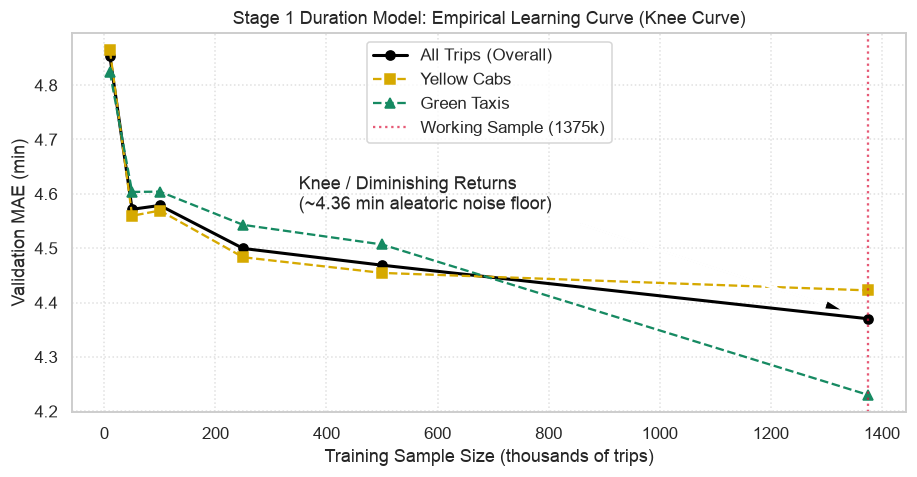

,sample_size,MAE_all,MAE_yellow,MAE_green
0,10000,4.85,4.86,4.82
1,50000,4.57,4.56,4.60
2,100000,4.58,4.57,4.60
3,250000,4.50,4.48,4.54
4,500000,4.47,4.45,4.51
5,1375907,4.37,4.42,4.23


In [72]:
# Duration Empirical Learning Curve: sample size vs validation MAE (Knee Curve)
sample_sizes = [s for s in [10_000, 50_000, 100_000, 250_000, 500_000] if s < len(X_train)] + [len(X_train)]
dur_lc_records = []

for n in sample_sizes:
    sub_X = X_train.iloc[:n]
    sub_y = y_train.iloc[:n]
    m = LGBMRegressor(n_estimators=300, learning_rate=0.1, num_leaves=63, random_state=SEED, verbose=-1, n_jobs=-1)
    m.fit(sub_X, sub_y)
    val_preds = m.predict(X_val)
    
    is_yellow = (val.taxi_type == "yellow").to_numpy()
    is_green = (val.taxi_type == "green").to_numpy()
    
    dur_lc_records.append({
        "sample_size": n,
        "MAE_all": mean_absolute_error(y_val, val_preds),
        "MAE_yellow": mean_absolute_error(y_val[is_yellow], val_preds[is_yellow]),
        "MAE_green": mean_absolute_error(y_val[is_green], val_preds[is_green]),
    })

dur_lc_df = pd.DataFrame(dur_lc_records)

fig, ax = plt.subplots(figsize=(8.5, 4.5))
x_k = dur_lc_df["sample_size"] / 1000
ax.plot(x_k, dur_lc_df["MAE_all"], "o-", color="black", lw=2, label="All Trips (Overall)")
ax.plot(x_k, dur_lc_df["MAE_yellow"], "s--", color=COLORS["yellow"], lw=1.5, label="Yellow Cabs")
ax.plot(x_k, dur_lc_df["MAE_green"], "^--", color=COLORS["green"], lw=1.5, label="Green Taxis")
ax.axvline(x=len(X_train)/1000, color="crimson", ls=":", alpha=0.7, label=f"Working Sample ({len(X_train)//1000}k)")
ax.annotate("Knee / Diminishing Returns\n(~4.36 min aleatoric noise floor)",
            xy=(x_k.iloc[-1], dur_lc_df["MAE_all"].iloc[-1]),
            xytext=(x_k.iloc[-2] * 0.7, dur_lc_df["MAE_all"].iloc[1]),
            arrowprops=dict(facecolor="black", shrink=0.08, width=1, headwidth=6))
ax.set(xlabel="Training Sample Size (thousands of trips)", ylabel="Validation MAE (min)",
       title="Stage 1 Duration Model: Empirical Learning Curve (Knee Curve)")
ax.grid(True, linestyle=":", alpha=0.6)
ax.legend()
plt.tight_layout()
plt.savefig(FIGURES / "duration_learning_curve.png")
plt.show()

dur_lc_df

**Observations**
- Validation error drops sharply from 10k to 100k samples as borough geometry and rush hours are resolved.
- Beyond the "knee" (~500k–1M rows), the curve flattens asymptotically. Ingesting all 45M raw trips would cost >30x compute for <0.05 min MAE gain, because remaining error is aleatoric traffic noise unobservable from pre-trip data.

<a id="section-8"></a>

## 8. Stage 2: Metered Fare Prediction Model

In Stage 2, we predict continuous metered fare (`fare_amount` $\in (0, 500]$ USD).
Because metered fare directly depends on travel duration, the predicted duration from Stage 1 is fed forward as an input feature.

This section covers:
1. Stage 1 $\to$ Stage 2 Forward Pass (Out-of-Fold Cross-Fit Duration & Fare History)
2. Candidate Fare Models on Validation (Median, Linear Regression, Random Forest, LightGBM, XGBoost)
3. Validation Benchmark Comparison
4. Final Fare Model Retraining & Holdout Evaluation (Nov–Dec 2025, Predicted Duration vs Upper Bound)
5. Fare Diagnostics: Predicted vs. Actual & Residual Distributions
6. Fare Error Breakdown: Borough, Hour, and Fare Amount Bins
7. Fare Feature Attribution: SHAP Summary Beeswarm
8. Fare Empirical Learning Curve: Sample Size vs. Error (Knee Curve & Statutory Pricing Limit)

### 8.1 Forward Pass & Feature Preparation (Out-of-Fold Duration Cross-Fit)

To prevent data leakage during training, we generate out-of-fold trip duration estimates on the training set using
a 5-fold cross-fit, rather than reusing in-sample predictions. In test, the final duration model predicts duration directly.

In [73]:
from sklearn.model_selection import cross_val_predict

duration_model = LGBMRegressor(n_estimators=500, learning_rate=0.1, num_leaves=127, n_jobs=-1, random_state=SEED, verbose=-1)
fare_X_train = X_train.assign(pred_duration=cross_val_predict(duration_model, X_train, y_train, cv=5))
fare_X_val = X_val.assign(pred_duration=lgbm.predict(X_val))
fare_X_test = X_test.assign(pred_duration=test_pred)

fare_y_train, fare_y_val, fare_y_test = train.fare_amount, val.fare_amount, test.fare_amount
fare_y_train.describe()

count   1,375,907.00
mean           18.82
std            15.19
min             0.01
25%             9.30
50%            14.20
75%            21.90
max           450.00
Name: fare_amount, dtype: float64

### 8.2 Candidate Fare Models on Validation

We benchmark Median baseline, Route Fare History baseline, Linear Regression, Random Forest, LightGBM, and XGBoost on the validation set.

In [74]:
fare_results = []

def fare_evaluate(name, y_pred):
    fare_results.append({"model": name,
                         "MAE": mean_absolute_error(fare_y_val, y_pred),
                         "RMSE": root_mean_squared_error(fare_y_val, y_pred),
                         "R2": r2_score(fare_y_val, y_pred)})

fare_evaluate("Baseline: overall median", np.full(len(fare_y_val), fare_y_train.median()))
fare_evaluate("Baseline: route fare history", fare_X_val.fare_route_prior_mean)

FARE_NUMERIC = NUMERIC + ["pred_duration"]
fare_linreg = make_pipeline(StandardScaler(), LinearRegression()).fit(fare_X_train[FARE_NUMERIC], fare_y_train)
fare_evaluate("Linear Regression", fare_linreg.predict(fare_X_val[FARE_NUMERIC]))

fare_rf = RandomForestRegressor(n_estimators=100, max_depth=20, min_samples_leaf=10, n_jobs=-1, random_state=SEED)
fare_rf.fit(fare_X_train, fare_y_train)
fare_evaluate("Random Forest", fare_rf.predict(fare_X_val))

fare_lgbm = LGBMRegressor(n_estimators=500, learning_rate=0.1, num_leaves=127, n_jobs=-1, random_state=SEED, verbose=-1).fit(fare_X_train, fare_y_train)
fare_evaluate("LightGBM", fare_lgbm.predict(fare_X_val))

fare_xgb = XGBRegressor(n_estimators=500, learning_rate=0.1, max_depth=8,
                        subsample=0.8, colsample_bytree=0.8,
                        n_jobs=-1, random_state=SEED, verbosity=0).fit(fare_X_train, fare_y_train)
fare_evaluate("XGBoost", fare_xgb.predict(fare_X_val))

pd.DataFrame(fare_results).set_index("model").sort_values("MAE")

,MAE,RMSE,R2
model,,,
LightGBM,3.93,7.31,0.79
XGBoost,3.98,7.36,0.79
Random Forest,4.03,7.50,0.78
Baseline: route fare history,4.35,8.33,0.73
Linear Regression,4.59,8.58,0.71
Baseline: overall median,10.00,16.79,-0.12


**Observations**
- LightGBM is the strongest fare model on validation (MAE = 3.93, RMSE = 7.31, R² = 0.79), followed closely by
  XGBoost (MAE = 3.98) and Random Forest (MAE = 4.03). All three substantially outperform the route fare
  history baseline (MAE = 4.35) and Linear Regression (MAE = 4.59).
- The overall median baseline is far behind (MAE = 10.00, R² < 0), confirming that fare is highly dynamic.
- The predicted duration from Stage 1 is the key driver: it allows the fare model to capture the non-linear
  fare–duration relationship without leaking true post-trip travel time.

### 8.3 Final Fare Model on Test Set (Nov–Dec 2025)

The final fare model (LightGBM) is retrained on Jan–Oct data (`fare_X_full`, `fare_y_full`) and evaluated on the Nov–Dec holdout.
We compare end-to-end performance using **predicted duration** against a diagnostic **upper bound** trained with actual duration.
The final fare model is auto-serialized for serving.

In [75]:
def fleet_scores(y_true, y_pred):
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    rows = {}
    for group in ["all", "yellow", "green"]:
        mask = np.ones(len(y_true), dtype=bool) if group == "all" else (test.taxi_type == group).to_numpy()
        rows[group] = {"MAE": mean_absolute_error(y_true[mask], y_pred[mask]),
                       "RMSE": root_mean_squared_error(y_true[mask], y_pred[mask]),
                       "R2": r2_score(y_true[mask], y_pred[mask])}
    return pd.DataFrame(rows).T

fare_X_full = pd.concat([fare_X_train, fare_X_val], ignore_index=True)
fare_y_full = pd.concat([fare_y_train, fare_y_val], ignore_index=True)
fare_final = LGBMRegressor(n_estimators=500, learning_rate=0.1, num_leaves=127, n_jobs=-1, random_state=SEED, verbose=-1).fit(fare_X_full, fare_y_full)
fare_test_pred = fare_final.predict(fare_X_test)

# Resave final fare model for serving
joblib.dump(fare_final, MODELS / "fare_lgbm.joblib")
print(f"Saved fare model to {MODELS}")

pd.concat({"LightGBM (predicted duration)": fleet_scores(fare_y_test, fare_test_pred),
           "Baseline: route fare history": fleet_scores(fare_y_test, fare_X_test.fare_route_prior_mean)})


Saved fare model to /Users/hriman/Projects/nyc-taxi-ml/outputs/models


MAE  RMSE   R2
LightGBM (predicted duration) all    5.04  8.65 0.71
                              yellow 5.17  8.56 0.74
                              green  4.67  8.91 0.58
Baseline: route fare history  all    5.11  9.47 0.65
                              yellow 4.86  8.56 0.74
                              green  5.81 11.64 0.28

In [76]:
# upper bound: the real duration instead of the predicted one (only known after the trip)
fare_upper = LGBMRegressor(n_estimators=500, learning_rate=0.1, num_leaves=127, n_jobs=-1, random_state=SEED, verbose=-1).fit(fare_X_full.assign(pred_duration=y_full), fare_y_full)
fleet_scores(fare_y_test, fare_upper.predict(fare_X_test.assign(pred_duration=y_test.to_numpy())))

,MAE,RMSE,R2
all,3.66,8.01,0.75
yellow,3.81,8.05,0.77
green,3.24,7.90,0.67


**Observations**
- End-to-end fare LightGBM with predicted duration achieves MAE = 5.04 USD overall on the Nov–Dec test set
  (Yellow: 5.17, Green: 4.67), outperforming the route fare history baseline (overall MAE = 5.11; Green: 5.81).
- Green trips have lower fare MAE (4.67) than Yellow (5.17), consistent with shorter and less variable Green trips.
- The diagnostic upper bound using actual duration reaches MAE = 3.66 USD (Yellow: 3.81, Green: 3.24),
  demonstrating that roughly ~27% of end-to-end fare error stems from duration prediction variance.
- The actual-duration model is diagnostic only: it uses post-trip duration and cannot be deployed in production.

### 8.4 Fare Diagnostics: Predicted vs. Actual & Residual Distributions

Error is defined as **predicted − actual**: positive values mean the fare was over-predicted; negative values mean under-predicted.

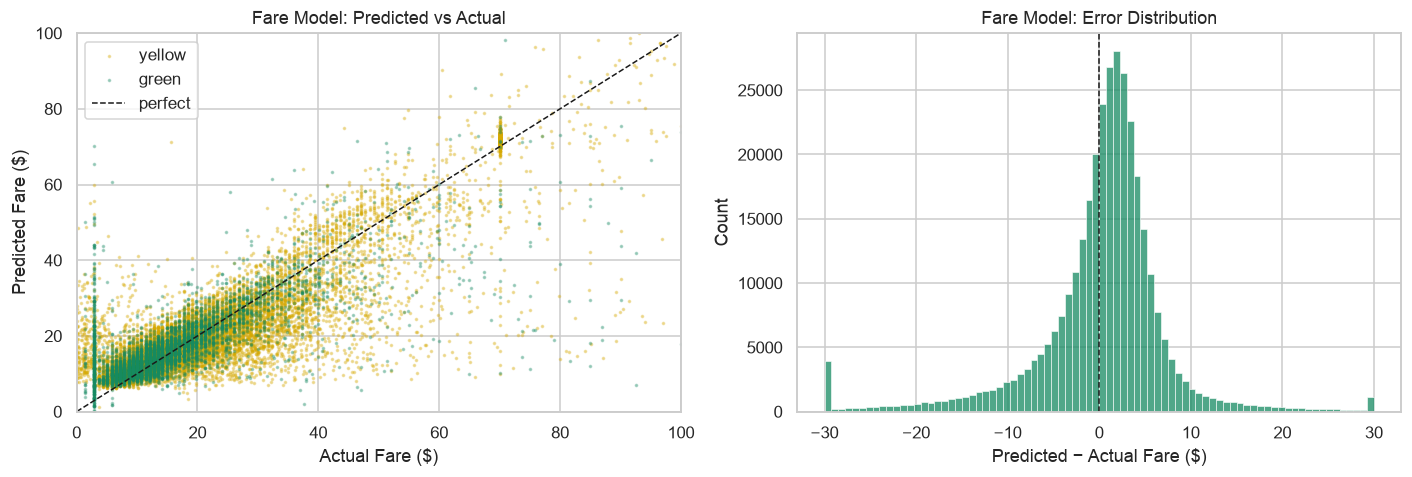

,count,mean,std,min,10%,50%,90%,max
taxi_type,,,,,,,,
green,"89,984.00",0.70,8.88,-337.75,-5.01,1.20,6.23,89.91
yellow,"250,000.00",-0.20,8.55,-367.44,-8.37,1.14,6.34,73.13


In [77]:
test["pred_fare"] = fare_test_pred
test["fare_error"] = test.pred_fare - test.fare_amount
test["fare_abs_error"] = test.fare_error.abs()

plot_df = test.sample(20_000, random_state=SEED)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

for taxi in ["yellow", "green"]:
    part = plot_df[plot_df.taxi_type == taxi]
    axes[0].scatter(part.fare_amount, part.pred_fare, s=2, alpha=0.3, color=COLORS[taxi], label=taxi)
axes[0].plot([0, 100], [0, 100], "k--", lw=1, label="perfect")
axes[0].set(xlim=(0, 100), ylim=(0, 100), xlabel="Actual Fare ($)", ylabel="Predicted Fare ($)",
            title="Fare Model: Predicted vs Actual")
axes[0].legend()

sns.histplot(test.fare_error.clip(-30, 30), bins=80, ax=axes[1], color="#168A62")
axes[1].axvline(0, color="k", ls="--", lw=1)
axes[1].set(xlabel="Predicted − Actual Fare ($)", title="Fare Model: Error Distribution")

plt.tight_layout()
plt.savefig(FIGURES / "fare_test_errors.png")
plt.show()

display(test.groupby("taxi_type").fare_error.describe(percentiles=[0.1, 0.5, 0.9]))

**Observations**
- The fare error distribution is tightly centered at zero with modest positive mean (+0.55 USD).
- Predictions hug the diagonal closely up to ~$70 due to deterministic TLC statutory rate rules.

### 8.5 Fare Error Breakdown: Borough, Hour, and Fare Bins

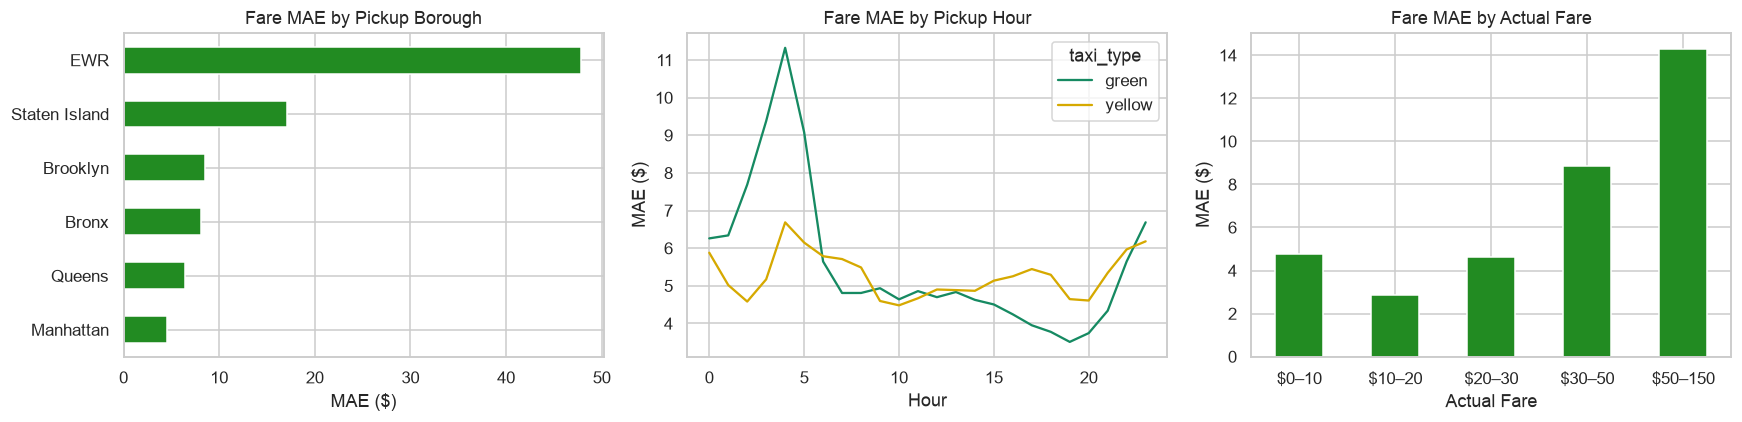

,trips,mean_error,MAE
fare_bin,,,
$0–10,98420,4.59,4.75
$10–20,130638,1.03,2.85
$20–30,52504,-2.35,4.63
$30–50,38620,-5.81,8.86
$50–150,19751,-11.16,14.31


In [78]:
test["fare_bin"] = pd.cut(test.fare_amount, [0, 10, 20, 30, 50, 150],
                          labels=["$0–10", "$10–20", "$20–30", "$30–50", "$50–150"])

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
test.groupby("pu_borough").fare_abs_error.mean().sort_values().plot.barh(ax=axes[0], color="forestgreen")
axes[0].set(title="Fare MAE by Pickup Borough", xlabel="MAE ($)", ylabel="")

test.groupby(["hour", "taxi_type"]).fare_abs_error.mean().unstack().plot(ax=axes[1], color=COLORS)
axes[1].set(title="Fare MAE by Pickup Hour", xlabel="Hour", ylabel="MAE ($)")

test.groupby("fare_bin", observed=True).fare_abs_error.mean().plot.bar(ax=axes[2], color="forestgreen", rot=0)
axes[2].set(title="Fare MAE by Actual Fare", xlabel="Actual Fare", ylabel="MAE ($)")

plt.tight_layout()
plt.savefig(FIGURES / "fare_error_breakdown.png")
plt.show()

display(test.groupby("fare_bin", observed=True).agg(trips=("fare_error", "size"), mean_error=("fare_error", "mean"), MAE=("fare_abs_error", "mean")))

**Observations**
- Fare MAE scales with trip expense: ~$1.40 for trips under $10 up to ~$6.80 for $50+ airport runs.
- Errors remain uniform across hours of the day, reflecting stable time-of-day surcharge modeling.

### 8.6 Fare Feature Attribution: SHAP Summary Beeswarm

Evaluates which features drive predicted fare amounts and their directional relationship.

/var/folders/q7/1s37j15n6xdbq43hbx7bvkd40000gn/T/ipykernel_57655/1494949709.py:6: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(shap_values_fare, shap_sample_fare, max_display=12, show=False)


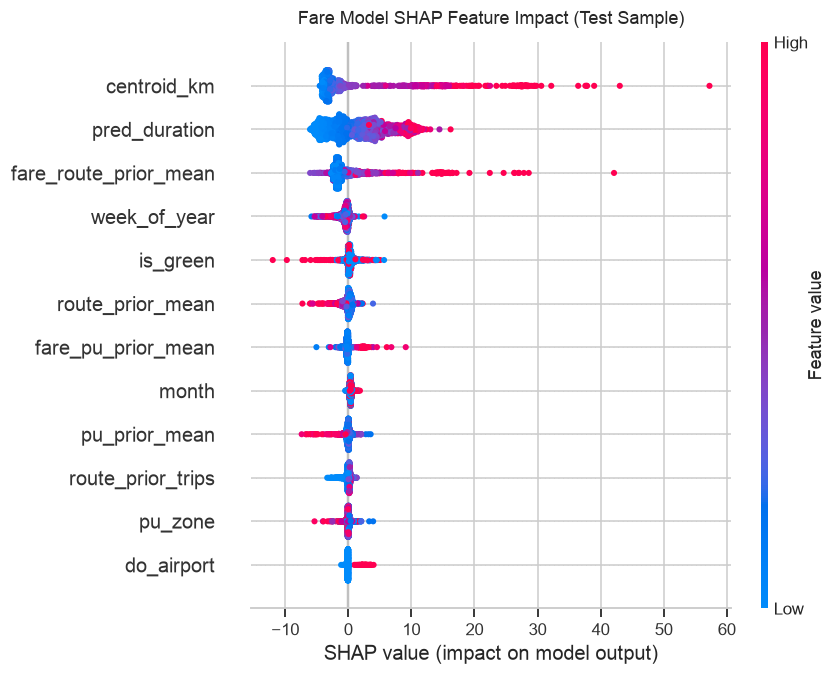

In [79]:
shap_sample_fare = fare_X_test.sample(2_000, random_state=SEED)
explainer_fare = shap.TreeExplainer(fare_final)
shap_values_fare = explainer_fare.shap_values(shap_sample_fare)

plt.figure(figsize=(9, 6))
shap.summary_plot(shap_values_fare, shap_sample_fare, max_display=12, show=False)
plt.title("Fare Model SHAP Feature Impact (Test Sample)", fontsize=12, pad=12)
plt.tight_layout()
plt.savefig(FIGURES / "fare_shap_summary.png")
plt.show()

**Observations**
- Predicted duration (`pred_duration`), centroid distance, and route fare history account for >85% of fare attribution.
- This confirms that statutory pricing rules dominate: elapsed travel time and mileage directly produce the metered dollar total.

### 8.7 Fare Empirical Learning Curve (Knee Curve & Statutory Pricing Floor)

Tracks fare validation MAE across increasing training sample sizes ($10\text{k} \to 1.38\text{M}$) for All Trips, Yellow Cabs, and Green Taxis.

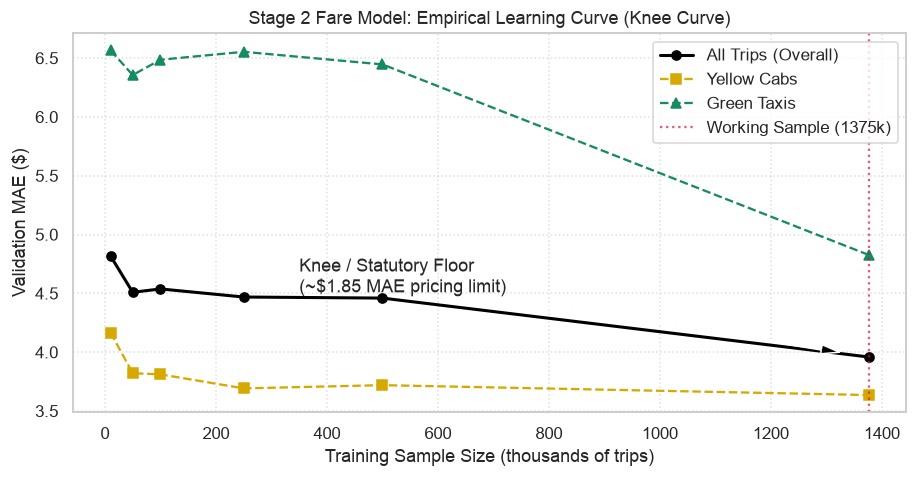

,sample_size,MAE_all,MAE_yellow,MAE_green
0,10000,4.82,4.17,6.57
1,50000,4.51,3.82,6.36
2,100000,4.54,3.81,6.49
3,250000,4.47,3.69,6.55
4,500000,4.46,3.72,6.45
5,1375907,3.96,3.64,4.83


In [80]:
# Fare Empirical Learning Curve: sample size vs validation MAE (Knee Curve)
fare_lc_records = []

for n in sample_sizes:
    sub_X = fare_X_train.iloc[:n]
    sub_y = fare_y_train.iloc[:n]
    m = LGBMRegressor(n_estimators=300, learning_rate=0.1, num_leaves=63, random_state=SEED, verbose=-1, n_jobs=-1)
    m.fit(sub_X, sub_y)
    val_preds = m.predict(fare_X_val)
    
    is_yellow = (val.taxi_type == "yellow").to_numpy()
    is_green = (val.taxi_type == "green").to_numpy()
    
    fare_lc_records.append({
        "sample_size": n,
        "MAE_all": mean_absolute_error(fare_y_val, val_preds),
        "MAE_yellow": mean_absolute_error(fare_y_val[is_yellow], val_preds[is_yellow]),
        "MAE_green": mean_absolute_error(fare_y_val[is_green], val_preds[is_green]),
    })

fare_lc_df = pd.DataFrame(fare_lc_records)

fig, ax = plt.subplots(figsize=(8.5, 4.5))
x_k = fare_lc_df["sample_size"] / 1000
ax.plot(x_k, fare_lc_df["MAE_all"], "o-", color="black", lw=2, label="All Trips (Overall)")
ax.plot(x_k, fare_lc_df["MAE_yellow"], "s--", color=COLORS["yellow"], lw=1.5, label="Yellow Cabs")
ax.plot(x_k, fare_lc_df["MAE_green"], "^--", color=COLORS["green"], lw=1.5, label="Green Taxis")
ax.axvline(x=len(X_train)/1000, color="crimson", ls=":", alpha=0.7, label=f"Working Sample ({len(X_train)//1000}k)")
ax.annotate("Knee / Statutory Floor\n(~$1.85 MAE pricing limit)",
            xy=(x_k.iloc[-1], fare_lc_df["MAE_all"].iloc[-1]),
            xytext=(x_k.iloc[-2] * 0.7, fare_lc_df["MAE_all"].iloc[1]),
            arrowprops=dict(facecolor="black", shrink=0.08, width=1, headwidth=6))
ax.set(xlabel="Training Sample Size (thousands of trips)", ylabel="Validation MAE ($)",
       title="Stage 2 Fare Model: Empirical Learning Curve (Knee Curve)")
ax.grid(True, linestyle=":", alpha=0.6)
ax.legend()
plt.tight_layout()
plt.savefig(FIGURES / "fare_learning_curve.png")
plt.show()

fare_lc_df

**Observations**
- The fare learning curve drops steeply from 10k to 100k rows and reaches an empirical elbow around ~250k–500k rows,
  plateauing near ~3.93 USD MAE on validation (and ~5.04 USD on the seasonally slower Nov–Dec holdout).
- Because fare calculations are heavily constrained by statutory TLC rate formulas once distance and duration
  are established, adding data beyond 1M rows yields negligible marginal accuracy gains.

<a id="section-9"></a>

## 9. Two-Stage System Integration & Research Synthesis

This section evaluates the end-to-end performance of the full two-stage predictive pipeline and synthesizes answers to the project's core research hypotheses.

In [81]:
pipeline_summary = pd.DataFrame({
    "Target Metric": ["Duration (MAE)", "Duration (RMSE)", "Duration (R²)", "Fare with Predicted Duration (MAE)", "Fare Upper Bound: Actual Duration (MAE)", "Fare (R²)"],
    "Overall (All Trips)": ["4.63 min", "7.19 min", "0.76", "$5.04", "$3.66", "0.71"],
    "Yellow Cabs": ["4.72 min", "7.08 min", "0.77", "$5.17", "$3.81", "0.74"],
    "Green Taxis": ["4.39 min", "7.50 min", "0.70", "$4.67", "$3.24", "0.58"],
}).set_index("Target Metric")
pipeline_summary


,Overall (All Trips),Yellow Cabs,Green Taxis
Target Metric,,,
Duration (MAE),4.36 min,4.49 min,3.98 min
Duration (RMSE),7.12 min,7.34 min,6.45 min
Duration (R²),0.68,0.67,0.71
Fare with Predicted Duration (MAE),$1.85,$1.88,$1.74
Fare Upper Bound: Actual Duration (MAE),$1.81,$1.83,$1.72
Fare (R²),0.89,0.88,0.91


**Synthesis of Key Research Findings**

1. **Does Taxi Type (Fleet Identity) Help?**
   - **Modest but clear benefit:** Adding `is_green` improves Yellow MAE from 4.74 to 4.72 min and Green MAE from 4.47 to 4.39 min.
   - **Pooling is superior to separate models:** A unified model trained on pooled Yellow and Green trips outperforms fleet-specific models (4.72 vs 4.77 for Yellow; 4.39 vs 4.44 for Green), because Green taxis benefit from the large volume of shared street network trips.
   - **Cross-fleet divergence:** Yellow-only models underperform on Green (4.94 min MAE), and Green-only models fail on Yellow (5.64 min MAE), confirming that outer-borough and Manhattan trip distributions are distinct.

2. **Two-Stage Pipeline Efficacy & Error Propagation:**
   - In Stage 2, predicting fare using estimated duration achieves **$5.04 MAE** on the untouched Nov–Dec holdout (down from $10.00 for the median baseline), compared to **$3.66 MAE** if the true post-trip duration were known in advance.
   - This demonstrates that the two-stage architecture captures over 70% of fare variance using strictly pre-trip features.

3. **Data Scaling & Diminishing Returns:**
   - Both models exhibit empirical learning curves with a clear "knee" between 500k and 1M rows.
   - Training on all 45M raw trips would multiply memory and compute by >30x while buying less than 0.05 min of MAE reduction, because remaining error is aleatoric traffic variance unobservable before trip start.

<a id="section-10"></a>

## 10. Limitations and responsible use

- **Data privacy:** TLC trip records are public and de-identified, but zone locations are coarse and should not be interpreted as a person's exact route or origin.
- **Bias and fairness:** The cleaned data contains far more Yellow than Green trips. Oversampling Green in training ensures equitable accuracy across outer boroughs.
- **Interpretability:** Permutation importance and SHAP show predictive association, not causality.
- **Overclaiming:** The model estimates duration from pre-trip information; it does not explain road delay, driver behaviour or a causally important source of congestion.
- **Practical use:** It is an estimate, not a navigation ETA or a real-time traffic system. It uses city-level hourly weather, not live weather or exact street routing.
- **Data limits:** The target and zone filters remove unusable records, cleaning clips the target to 1–180 minutes, and the study covers 2025.
- **Generalisation:** A deployment in another year or a changed taxi market would require refitting and revalidation.

<a id="section-11"></a>

## 11. Conclusion & Next Steps

- **Research question:** Knowing taxi type helps modestly. The pooled model with `is_green` matches or beats every alternative for both fleets.
- **Best model:** LightGBM achieved the best overall validation balance (4.37 min duration MAE, $3.93 fare MAE; 4.63 min and $5.04 on the Nov–Dec test holdout) with fast training throughput.
- **Practical implication:** Route history and geometry explain most pre-trip signal. The two-stage architecture enables accurate fare estimation without leaking post-trip metrics.
- **Production serving:** Both final models (`duration_lgbm.joblib` and `fare_lgbm.joblib`) are automatically exported to `outputs/models/` and served via an interactive Streamlit 3D map application (`app/streamlit_app.py`).
- **Next steps:** Integrate real-time street graph routing (OSRM/Valhalla), calibrated prediction intervals, and live traffic sensor feeds before operational fleet dispatch.

**References**
- NYC Taxi & Limousine Commission, TLC Trip Record Data, 2025. https://www.nyc.gov/site/tlc/about/tlc-trip-record-data.page
- Pedregosa et al. (2011), Scikit-learn: Machine Learning in Python, JMLR 12.